# Bank Product Recommender
**Which product will a bank customer sign up for next?**

Data: Santander Product Recommendation (Kaggle) — real, anonymized monthly records of ~950k bank customers across 24 products (Jan 2015 – May 2016).

Method: CRISP-DM
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modeling
5. Evaluation
6. Deployment

## 1. Business Understanding

### 1.1 Business context
Santander is one of Europe's largest retail banks. Like most banks, it earns more from customers who hold several products (a current account *plus* a credit card *plus* a savings product) than from customers who hold one. Selling an existing customer an additional product is called **cross-selling**, and it is usually cheaper than acquiring a new customer.

The problem: a bank has hundreds of thousands of customers and 24 products. Relationship managers (RMs) cannot pitch everything to everyone, so they need to know **which product each customer is most likely to want next**.

### 1.2 Business objective
Give each relationship manager a **monthly call list**: for every active customer, a ranked list of products they do not own yet, ordered by how likely they are to sign up next month.

- The RM pitches the **top 3** products on a call (a realistic number for one conversation).
- The full ranked list (up to 7) can be reused for lower-touch channels like an in-app banner or email.

### 1.3 Success criteria

| Level | Metric | What it means |
|---|---|---|
| **Primary (technical)** | **MAP@7** | Mean Average Precision over the top 7 recommendations. This was the official Kaggle metric, so our score is directly comparable to the competition leaderboard. It rewards putting the *right* product *high* in the list. |
| **Secondary (business)** | **Hit rate @ 3** | Among customers who actually opened a new product, the % whose new product was in our top 3. In plain terms: *"How often would the RM have pitched the right thing?"* Reported with **hit rate @ 1** (was the *first* pitch right?), added in 4.1. |

**Baseline to beat:** a *popularity* recommender, which gives every customer the most commonly added products they don't already own. If a model can't beat "recommend what's popular," it isn't worth deploying.

### 1.4 Product scope
- **Modeling and scoring:** all 24 products, so MAP@7 stays comparable to Kaggle.
- **RM call list:** filtered to products a bank can actually *pitch*. For example, **payroll** (a salary deposit) depends on the customer's employer paying into Santander, not on an RM's pitch. The final "not pitchable" list was decided in Data Understanding (see the findings under 2.5).

### 1.5 Data mining goal
Translate the business objective into a modeling task:

> For each customer active in month *T*, estimate the probability that they **add** each product they did **not** hold in month *T−1*, then rank those products.

We predict *additions*, not holdings. A customer who already has a credit card doesn't need it recommended again.

### 1.6 Assumptions and limitations
- **Real but anonymized data** from Spanish customers (Jan 2015 – May 2016). Patterns may not transfer directly to other markets.
- **No product prices or margins**, so we optimize for *likelihood of adoption*, not revenue.
- **No campaign history.** We don't know who was already pitched what, so we're modeling natural adoption, not response to an offer.
- **Most customers add nothing in a given month.** Scores will look small in absolute terms; that's expected for this problem.

### 1.7 Project plan
1. **Data Understanding:** load the data efficiently, profile customers and products, and find how often each product is added month-to-month.
2. **Data Preparation:** clean customer fields, build the "added a product" target, and engineer features (e.g., what the customer held last month, tenure, income, channel).
3. **Modeling:** popularity baseline → machine-learning ranker.
4. **Evaluation:** MAP@7 and hit rate @ 3 on a held-out month, plus what drives the recommendations.
5. **Deployment:** a sample RM call list and a short recommendation memo.

## 2. Data Understanding

### 2.1 Load the data
The training file has ~13.6M rows (one row per customer per month) and is 2.3 GB on disk. Loaded with default settings, pandas stores every text column as a generic Python object, which wastes memory.

So we tell pandas the column types up front:
- **24 product columns** (`ind_..._ult1`, 1 = customer holds the product that month) → `float32`. Not `int`, because two product columns have missing values and integers can't store NaN.
- **Repeated text codes** like sex, segment, province → `category`, which stores each distinct value once.
- **`age`, `antiguedad` (tenure), `ult_fec_cli_1t`** → kept as text for now. They contain stray spaces and placeholder values, which we'll inspect before converting.
- **Dates** (`fecha_dato` = snapshot month, `fecha_alta` = date the customer joined) → parsed as dates.

The first run reads the CSV (~100s) and saves a **Parquet** copy, a compressed column-based format that keeps these types. Later runs load the Parquet file in seconds.

In [1]:
import time
import numpy as np
import pandas as pd

DATA_PATH = "data/train_ver2.csv"
CACHE_PATH = "data/train.parquet"   # fast-loading copy, created on first run

# Read only the header first, to find the 24 product columns by name
header = pd.read_csv(DATA_PATH, nrows=0).columns
product_cols = [c for c in header if c.endswith("ult1")]

cat_cols = ["ind_empleado", "pais_residencia", "sexo", "indrel_1mes", "tiprel_1mes",
            "indresi", "indext", "conyuemp", "canal_entrada", "indfall", "nomprov", "segmento"]

dtypes = {c: "float32" for c in product_cols}
dtypes.update({c: "category" for c in cat_cols})
dtypes.update({
    "ncodpers": "int32",                # customer ID
    "ind_nuevo": "float32", "indrel": "float32", "tipodom": "float32",
    "cod_prov": "float32", "ind_actividad_cliente": "float32", "renta": "float32",
    "age": "str", "antiguedad": "str", "ult_fec_cli_1t": "str",
})

start = time.time()
try:
    df = pd.read_parquet(CACHE_PATH)
    source = "Parquet cache"
except FileNotFoundError:
    df = pd.read_csv(DATA_PATH, dtype=dtypes, parse_dates=["fecha_dato", "fecha_alta"])
    df.to_parquet(CACHE_PATH, index=False)
    source = "CSV (Parquet cache saved for next time)"
print(f"Loaded from {source} in {time.time() - start:.0f}s")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
print(f"Product columns: {len(product_cols)}")

Loaded from Parquet cache in 1s
Shape: 13,647,309 rows x 48 columns
Memory: 3.89 GB
Product columns: 24


### 2.2 Data dictionary
The column names are Spanish abbreviations. This table translates each one (from the Kaggle data description) and shows its type, how much is missing, and how many distinct values it has. Product names are saved in `PRODUCT_NAMES` so we can use readable labels in later charts.

In [2]:
COLUMN_MEANINGS = {
    "fecha_dato": "Snapshot month",
    "ncodpers": "Customer ID",
    "ind_empleado": "Employee status (A active, B ex-employee, F filial, N not employee, P passive)",
    "pais_residencia": "Country of residence",
    "sexo": "Sex",
    "age": "Age",
    "fecha_alta": "Date customer first opened a contract",
    "ind_nuevo": "New customer (joined in last 6 months)",
    "antiguedad": "Tenure in months",
    "indrel": "1 = primary customer, 99 = stopped being primary this month",
    "ult_fec_cli_1t": "Last date as primary customer (if they stopped)",
    "indrel_1mes": "Customer type at start of month (1 primary, 2 co-owner, P potential, 3/4 former)",
    "tiprel_1mes": "Relationship at start of month (A active, I inactive, P former, R potential)",
    "indresi": "Lives in same country as bank (S/N)",
    "indext": "Born in a different country (S/N)",
    "conyuemp": "Spouse of an employee",
    "canal_entrada": "Channel used to join",
    "indfall": "Deceased (S/N)",
    "tipodom": "Address type (1 = primary)",
    "cod_prov": "Province code",
    "nomprov": "Province name",
    "ind_actividad_cliente": "Active customer (1/0)",
    "renta": "Gross household income (EUR)",
    "segmento": "Segment (01 VIP, 02 individuals, 03 university students)",
}

PRODUCT_NAMES = {
    "ind_ahor_fin_ult1": "Savings account",
    "ind_aval_fin_ult1": "Guarantees",
    "ind_cco_fin_ult1": "Current account",
    "ind_cder_fin_ult1": "Derivatives account",
    "ind_cno_fin_ult1": "Payroll account",
    "ind_ctju_fin_ult1": "Junior account",
    "ind_ctma_fin_ult1": "Mas particular account",
    "ind_ctop_fin_ult1": "Particular account",
    "ind_ctpp_fin_ult1": "Particular Plus account",
    "ind_deco_fin_ult1": "Short-term deposit",
    "ind_deme_fin_ult1": "Medium-term deposit",
    "ind_dela_fin_ult1": "Long-term deposit",
    "ind_ecue_fin_ult1": "e-account",
    "ind_fond_fin_ult1": "Funds",
    "ind_hip_fin_ult1": "Mortgage",
    "ind_plan_fin_ult1": "Pension plan",
    "ind_pres_fin_ult1": "Loan",
    "ind_reca_fin_ult1": "Taxes",
    "ind_tjcr_fin_ult1": "Credit card",
    "ind_valo_fin_ult1": "Securities",
    "ind_viv_fin_ult1": "Home account",
    "ind_nomina_ult1": "Payroll (salary deposit)",
    "ind_nom_pens_ult1": "Pension (paid via payroll)",
    "ind_recibo_ult1": "Direct debit",
}

overview = pd.DataFrame({
    "meaning": [COLUMN_MEANINGS.get(c, PRODUCT_NAMES.get(c)) for c in df.columns],
    "dtype": df.dtypes.astype(str).values,
    "missing_%": (df.isna().mean() * 100).round(2).values,
    "n_unique": df.nunique().values,
}, index=df.columns)

pd.set_option("display.max_colwidth", 80)
overview

,meaning,dtype,missing_%,n_unique
fecha_dato,Snapshot month,datetime64[ns],0.00,17
ncodpers,Customer ID,int32,0.00,956645
ind_empleado,"Employee status (A active, B ex-employee, F filial, N not employee, P passive)",category,0.20,5
pais_residencia,Country of residence,category,0.20,118
sexo,Sex,category,0.20,2
age,Age,object,0.00,121
fecha_alta,Date customer first opened a contract,datetime64[ns],0.20,6756
ind_nuevo,New customer (joined in last 6 months),float32,0.20,2
antiguedad,Tenure in months,object,0.00,259
indrel,"1 = primary customer, 99 = stopped being primary this month",float32,0.20,2


### 2.3 The rows with a blank profile
About a dozen profile columns (sex, country, join date, segment...) are missing the **exact same ~0.20%**. Identical missing rates usually mean the *same rows* are blank everywhere. Here we check that, and look at who these rows are.

In [3]:
blank = df["ind_empleado"].isna()   # one profile column as the marker
print(f"Rows with a blank profile: {blank.sum():,} ({blank.mean():.2%} of all rows)")
print(f"Distinct customers in those rows: {df.loc[blank, 'ncodpers'].nunique():,}")

# 1. Inside these rows, how much of each column is missing?
#    If the profile columns are all ~100%, it's the same rows everywhere.
missing_inside = df.loc[blank].isna().mean().mul(100).round(1)
print("\nColumns that are fully blank in these rows:")
print(missing_inside[missing_inside == 100].index.tolist())

# 2. Which months do they appear in?
print("\nBlank-profile rows by month:")
print(df.loc[blank, "fecha_dato"].dt.strftime("%Y-%m").value_counts().sort_index())

# 3. Do these customers ever show up with a full profile in another month?
blank_ids = df.loc[blank, "ncodpers"].unique()
seen_complete = df.loc[~blank & df["ncodpers"].isin(blank_ids), "ncodpers"].nunique()
print(f"\nOf those customers, {seen_complete:,} appear with a full profile in another month")

# 4. Do they still hold products?
products_held = df[product_cols].sum(axis=1)
print(f"Avg products held, blank rows: {products_held[blank].mean():.2f}  vs  all rows: {products_held.mean():.2f}")

Rows with a blank profile: 27,734 (0.20% of all rows)
Distinct customers in those rows: 7,340

Columns that are fully blank in these rows:
['ind_empleado', 'pais_residencia', 'sexo', 'fecha_alta', 'ind_nuevo', 'indrel', 'ult_fec_cli_1t', 'indrel_1mes', 'tiprel_1mes', 'indresi', 'indext', 'conyuemp', 'canal_entrada', 'indfall', 'tipodom', 'cod_prov', 'nomprov', 'ind_actividad_cliente', 'renta', 'segmento']

Blank-profile rows by month:
fecha_dato
2015-01    6953
2015-02    5940
2015-03    5091
2015-04    4292
2015-05    3597
2015-06    1861
Name: count, dtype: int64

Of those customers, 309 appear with a full profile in another month
Avg products held, blank rows: 0.93  vs  all rows: 1.46


**Finding and decision**

- **What they are:** 27,734 rows (0.20%) from 7,340 customers where the *same 20 profile columns* are all blank. They appear only in Jan–Jun 2015, shrink every month, then disappear entirely.
- **They still hold products** (0.93 on average vs 1.46 overall). Product history matters because our features will compare what a customer holds *this* month with *last* month, so dropping rows would break that chain.
- **Decision (applied in Data Preparation):**
  1. **Keep all rows.**
  2. **309 customers** have a full profile in another month, so fill their blanks from their *own* other months (real data, different row).
  3. **The other ~7,000** never have a profile, so leave fields blank and add an *unknown profile* flag rather than inventing values.
- **Impact:** low. It's 0.2% of rows and none of these customers exist in the 2016 months we score. Checked before spending more time on it.

### 2.4 Age, tenure, and income
`age` and `antiguedad` (tenure) were loaded as text because they contained non-numeric values. Here we convert *copies* to numbers (the data itself isn't changed yet) and look for impossible or extreme values. `renta` (household income) is already numeric but is ~20% missing, so we check its spread too.

age: non-numeric values -> {'NA': 27734}
tenure: non-numeric values -> {'NA': 27734}

              age  tenure_months  income_eur
count  13619575.0     13619575.0  10852934.0
mean         40.2           76.6    134254.2
std          17.2         1671.8    226146.7
min           2.0      -999999.0      1202.7
1%           19.0            1.0     26449.7
50%          39.0           50.0    101850.0
99%          88.0          232.0    554795.0
max         164.0          256.0  28894396.0

Age under 18: 118,796 rows | Age over 100: 12,869 rows
Tenure below 0: 38 rows, values: [-999999.]


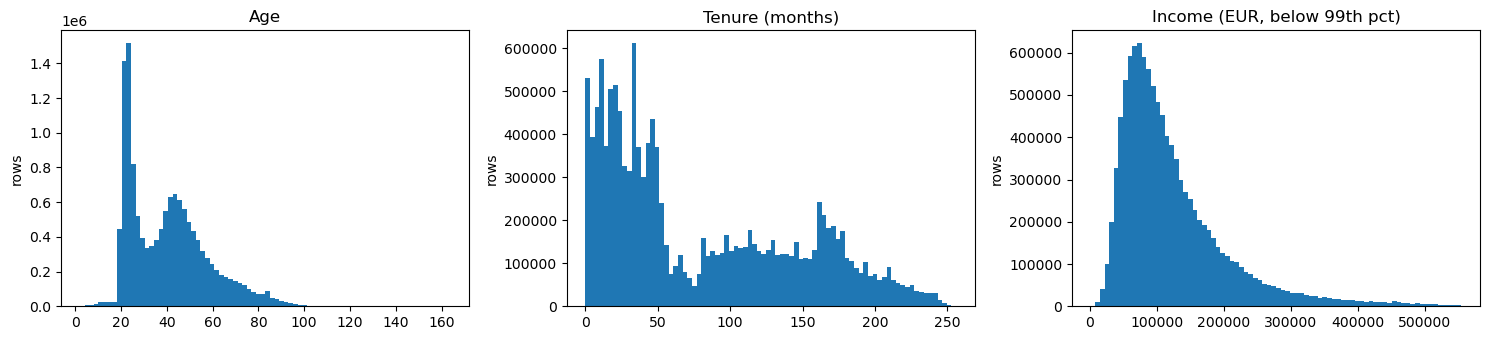

In [4]:
import matplotlib.pyplot as plt

age = pd.to_numeric(df["age"].str.strip(), errors="coerce")
tenure = pd.to_numeric(df["antiguedad"].str.strip(), errors="coerce")
income = df["renta"]

# What text values failed to convert?
for name, raw, num in [("age", df["age"], age), ("tenure", df["antiguedad"], tenure)]:
    bad = raw.str.strip()[num.isna()].value_counts()
    print(f"{name}: non-numeric values -> {bad.to_dict()}")

summary = pd.DataFrame({
    "age": age.describe(percentiles=[.01, .5, .99]),
    "tenure_months": tenure.describe(percentiles=[.01, .5, .99]),
    "income_eur": income.describe(percentiles=[.01, .5, .99]),
}).round(1)
print()
print(summary)

print(f"\nAge under 18: {(age < 18).sum():,} rows | Age over 100: {(age > 100).sum():,} rows")
print(f"Tenure below 0: {(tenure < 0).sum():,} rows, values: {tenure[tenure < 0].unique()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
age.plot.hist(bins=80, ax=axes[0], title="Age")
tenure[tenure >= 0].plot.hist(bins=80, ax=axes[1], title="Tenure (months)")
income[income < income.quantile(0.99)].plot.hist(bins=80, ax=axes[2], title="Income (EUR, below 99th pct)")
for ax in axes:
    ax.set_ylabel("rows")
plt.tight_layout()
plt.show()

**Findings and decisions**

| Field | Finding | Decision (applied in Data Preparation) |
|---|---|---|
| `age`, `antiguedad` | The `NA` text appears in exactly **27,734** rows, the same blank-profile rows from 2.3. Not a new problem. | Handled by the 2.3 decision. |
| `age` (young) | 118,796 rows are under 18 (youngest: 2). **91% of them hold a Junior account**, vs 0.16% of adults. These are real children with accounts opened by parents. | Keep as is. |
| `age` (old) | 12,869 rows over 100, tailing off smoothly to ~117, then a few impossible values (126, 127, 163, 164). | Cap at 100. For recommending products, a 104-year-old and a "164-year-old" belong in the same "very elderly" group. |
| `antiguedad` | 38 rows have tenure **-999999**. That's a *sentinel value*, a placeholder an old system uses for "unknown". It also explains the huge std (1,672 months) next to a mean of 77. | Treat as missing. |
| `renta` | Right-skewed: median ~€102k, mean ~€134k, max €28.9M. Plausibly very wealthy households, not errors. ~20% missing. | Keep high values (tree-based models aren't thrown off by skew). Plan for the 20% missing in Data Preparation. |

### 2.5 How often are products *added*?
This is the thing we're predicting. A product counts as **added** when a customer holds it this month but did **not** hold it the month before.

How it's computed:
1. Sort rows by customer, then month.
2. For each row, look at the same customer's row from the **previous calendar month**. If the customer skipped a month or it's their first month, there's nothing to compare, so no addition is counted.
3. `added = holds now AND did not hold last month`.

We look at it three ways: per month, per product, and product by month (to spot seasonality).

In [5]:
# 1. Line up each row with the same customer's previous month
df = df.sort_values(["ncodpers", "fecha_dato"]).reset_index(drop=True)
month_idx = (df["fecha_dato"].dt.year - 2015) * 12 + df["fecha_dato"].dt.month   # Jan 2015 = 1

same_customer = df["ncodpers"].eq(df["ncodpers"].shift(1))
consecutive = month_idx.eq(month_idx.shift(1) + 1)
has_prev = (same_customer & consecutive).to_numpy()

now = df[product_cols].to_numpy()
prev = df[product_cols].shift(1).to_numpy()

# 2. Added = holds it now, didn't hold it last month (only where a previous month exists)
added = pd.DataFrame((now == 1) & (prev == 0) & has_prev[:, None],
                     columns=product_cols, index=df.index)
added["fecha_dato"] = df["fecha_dato"]

n_added = added[product_cols].sum(axis=1)
print(f"Rows with a previous month to compare: {has_prev.sum():,}")
print(f"Total product additions: {int(n_added.sum()):,}")
print(f"Share of customer-months with at least one addition: {(n_added[has_prev] > 0).mean():.2%}")

Rows with a previous month to compare: 12,682,421
Total product additions: 561,710
Share of customer-months with at least one addition: 3.52%


            customers  added_any  additions  pct_added_any
fecha_dato                                                
2015-02        622926      23782      31372           3.82
2015-03        625094      25197      31948           4.03
2015-04        626698      25496      30427           4.07
2015-05        628135      21203      26311           3.38
2015-06        628603      33318      41745           5.30
2015-07        630249      26097      33362           4.14
2015-08        828361      24326      29490           2.94
2015-09        841795      28479      35696           3.38
2015-10        863690      32208      39803           3.73
2015-11        890170      28036      35215           3.15
2015-12        904294      33684      42353           3.72
2016-01        908930      26268      30956           2.89
2016-02        914329      36071      49024           3.95
2016-03        919070      27735      35203           3.02
2016-04        923414      26736      32962           2.

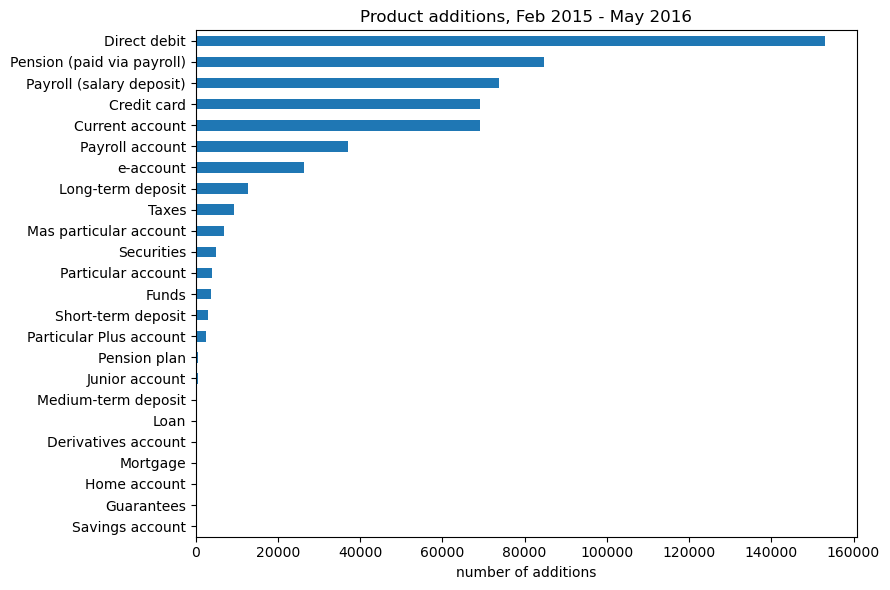

,additions,share_%
Direct debit,153146,27.26
Pension (paid via payroll),84709,15.08
Payroll (salary deposit),73753,13.13
Credit card,69118,12.30
Current account,69103,12.30
Payroll account,37098,6.60
e-account,26361,4.69
Long-term deposit,12659,2.25
Taxes,9234,1.64
Mas particular account,6856,1.22


In [6]:
# 3a. Per month: what share of customers added something?
monthly = pd.DataFrame({
    "customers": has_prev,
    "added_any": (n_added > 0) & has_prev,
    "additions": n_added,
}).groupby(df["fecha_dato"]).sum()
monthly.index = monthly.index.strftime("%Y-%m")
monthly["pct_added_any"] = (monthly["added_any"] / monthly["customers"] * 100).round(2)
print(monthly.iloc[1:])   # skip Jan 2015: no previous month to compare

# 3b. Per product: which products get added most?
by_product = (added[product_cols].sum()
              .rename(PRODUCT_NAMES)
              .sort_values(ascending=False))
by_product_pct = (by_product / by_product.sum() * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 6))
by_product.sort_values().plot.barh(ax=ax)
ax.set_title("Product additions, Feb 2015 - May 2016")
ax.set_xlabel("number of additions")
plt.tight_layout()
plt.show()
pd.DataFrame({"additions": by_product, "share_%": by_product_pct})

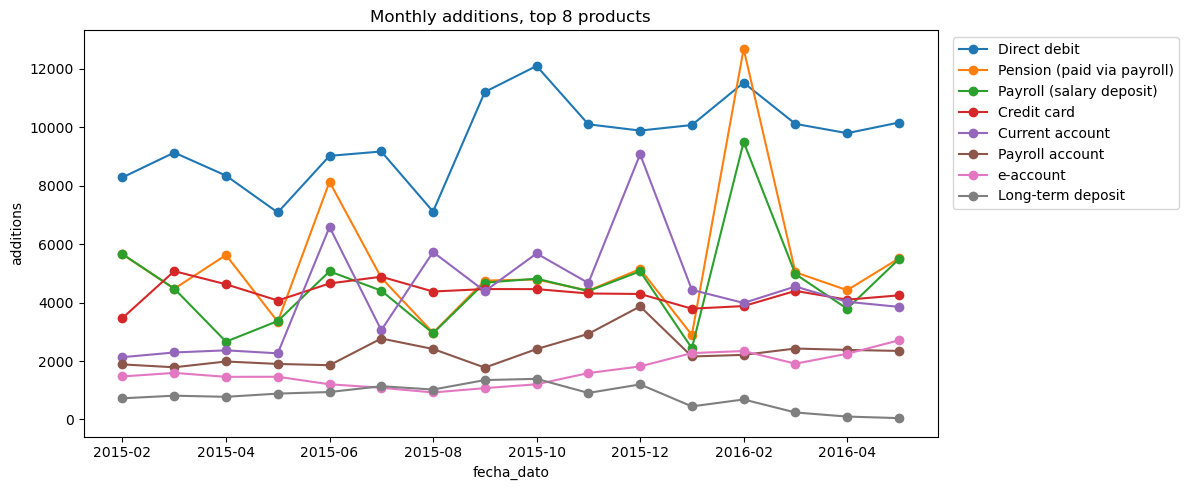

In [7]:
# 3c. Product by month: are there seasonal spikes?
top_products = by_product.index[:8]
name_to_col = {v: k for k, v in PRODUCT_NAMES.items()}

by_month = (added.groupby("fecha_dato")[[name_to_col[n] for n in top_products]]
            .sum().iloc[1:]
            .rename(columns=PRODUCT_NAMES))
by_month.index = by_month.index.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(12, 5))
by_month.plot(ax=ax, marker="o")
ax.set_title("Monthly additions, top 8 products")
ax.set_ylabel("additions")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Findings and decisions**

1. **Additions are rare.** Only **3.52%** of customer-months add any product. The other 96.5% of the time the right answer is "nothing new."
   - This is why MAP@7 scores are small (customers who add nothing count as zero), and it's a *class imbalance* problem for the model: the examples we care about are a small minority.
   - Decision deferred to Data Preparation: how to train on a target this rare.

2. **Additions are concentrated.** The top 5 products (direct debit, payroll pension, payroll, credit card, current account) make up **~80%** of all additions. Nine products were added fewer than 1,000 times in 16 months, across ~900k customers.

3. **Payroll and payroll pension move together** and spike sharply in **Feb 2016** (pension 12,687 vs ~5,000 in a normal month). A spike that size, in two employer-linked products at once, looks like an outside event (e.g., an employer or pension batch moving to the bank), not RM selling. Other spikes: current account in Jun 2015 and Dec 2015.
   - Decision: seasonality matters, so the **evaluation month will be chosen deliberately** (Phase 4), not at random.

**RM call list scope (completes Section 1.4).** The model still scores all 24 products for MAP@7. The RM's list excludes:

| Reason | Products |
|---|---|
| Driven by the employer, not by a pitch | Payroll (salary deposit), Pension (paid via payroll) |
| Almost never added (< 1,000 times in 16 months) | Pension plan, Junior account, Medium-term deposit, Loan, Derivatives account, Mortgage, Home account, Guarantees, Savings account |

That leaves **13 pitchable products** on the RM list.

### 2.6 Who adds what?
Now we break additions down by customer type: **age group**, **segment**, and **income band**. For each group we compute an **addition rate**: out of every 1,000 customer-months, how many added that product.

We use rates, not raw counts, because groups differ a lot in size. A big group will have more additions just because it's big.

Only the **13 pitchable products** are shown, since those are what the RM list will contain. If a customer type clearly prefers certain products, that column is likely to be a useful feature for the model.

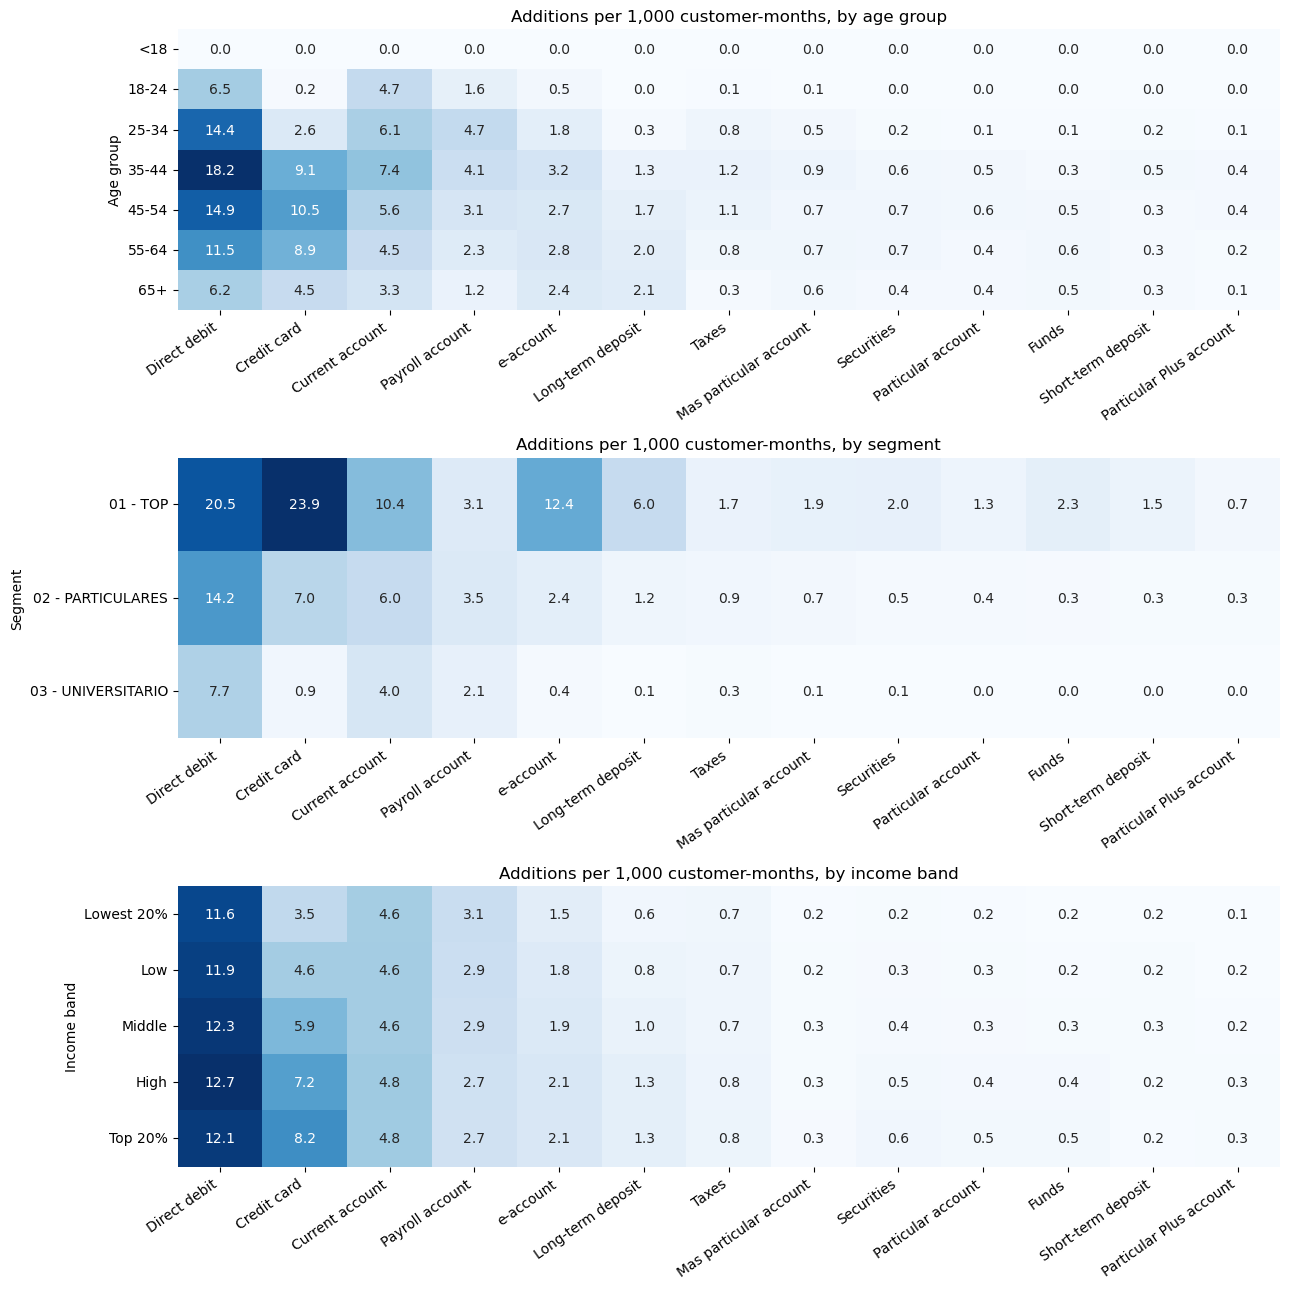

In [8]:
import seaborn as sns

NOT_PITCHABLE = ["ind_nomina_ult1", "ind_nom_pens_ult1",            # employer-driven
                 "ind_plan_fin_ult1", "ind_ctju_fin_ult1", "ind_deme_fin_ult1", "ind_pres_fin_ult1",
                 "ind_cder_fin_ult1", "ind_hip_fin_ult1", "ind_viv_fin_ult1", "ind_aval_fin_ult1",
                 "ind_ahor_fin_ult1"]                                 # almost never added
pitchable_cols = [c for c in product_cols if c not in NOT_PITCHABLE]

# Customer groups (recomputed here because df was re-sorted in 2.5)
age_num = pd.to_numeric(df["age"].str.strip(), errors="coerce").clip(upper=100)
groups = {
    "Age group": pd.cut(age_num, bins=[0, 17, 24, 34, 44, 54, 64, 100],
                        labels=["<18", "18-24", "25-34", "35-44", "45-54", "55-64", "65+"]),
    "Segment": df["segmento"].cat.remove_unused_categories(),
    "Income band": pd.qcut(df["renta"], 5, labels=["Lowest 20%", "Low", "Middle", "High", "Top 20%"]),
}

# Order products by overall popularity so the three charts line up
order = added.loc[has_prev, pitchable_cols].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(3, 1, figsize=(13, 13))
for ax, (title, g) in zip(axes, groups.items()):
    rate = (added.loc[has_prev, order]
            .groupby(g[has_prev], observed=True).mean() * 1000)
    rate.columns = [PRODUCT_NAMES[c] for c in order]
    sns.heatmap(rate, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"Additions per 1,000 customer-months, by {title.lower()}")
    ax.set_ylabel(title)
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)
    plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.savefig("images/additions_by_customer_type.png", dpi=150, bbox_inches="tight")   # used in the README
plt.show()

**Findings**

1. **Segment matters most.** VIP ("01 - TOP") customers add more of almost everything. The biggest gap is **credit cards**: 23.9 per 1,000 for VIPs vs 0.9 for university students, about 26x.
2. **Income matters for some products, not others.** Credit card additions rise steadily with income (3.5 → 8.2 per 1,000 from the lowest to the top 20%), but **direct debit stays flat** (~12 per 1,000 in every band). Paying bills is universal; getting approved for credit depends on earnings.
3. **Age peaks in the middle.** Customers aged 35–54 add the most, especially direct debit and credit cards. Under-18s add none of the pitchable products (their accounts are opened by parents).

**So what for the RM:** *Pitch credit cards to VIP and higher-income customers aged 35–64. For students and young customers, lead with direct debit and a current account.*

**So what for the model:** a one-size-fits-all "most popular" list would push credit cards to students, who almost never add them. That's exactly the gap a personalized model should close. Segment, income, and age are all likely to be useful features.

### Data Understanding: summary
| # | Finding | Where it goes next |
|---|---|---|
| 1 | 27,734 blank-profile rows (0.2%), only in early 2015 | Keep; fill 309 customers from their own history; flag the rest (Prep) |
| 2 | Age 2–164, tenure sentinel -999999 | Cap age at 100; tenure sentinel → missing (Prep) |
| 3 | Income right-skewed and ~20% missing | Keep high values; handle missing (Prep) |
| 4 | Only 3.52% of customer-months add any product | Class imbalance; choose a training approach (Prep/Modeling) |
| 5 | Top 5 products = ~80% of additions; Feb 2016 payroll spike | 13 pitchable products on the RM list; choose evaluation month deliberately (Modeling) |
| 6 | Segment, income, age shape *which* product is added | Core customer features (Prep) |

## 3. Data Preparation

### 3.1 Apply the cleaning decisions from Data Understanding
Everything here was already decided in Phase 2. This cell just turns those decisions into code:

| Decision | From |
|---|---|
| `age` and `antiguedad` (tenure) → numbers | 2.4 |
| Cap age at 100 | 2.4 |
| Tenure sentinel `-999999` → missing | 2.4 |
| 309 blank-profile customers: fill from their **own** other months | 2.3 |
| Remaining blank profiles: leave blank, add a `profile_unknown` flag | 2.3 |
| Drop `conyuemp` (spouse of employee, ~100% empty) | 2.2 |

We print a before/after check for each step so we can confirm it did what we expected.

In [9]:
# 1. Age and tenure: text -> numbers
df["age"] = pd.to_numeric(df["age"].str.strip(), errors="coerce")
df["antiguedad"] = pd.to_numeric(df["antiguedad"].str.strip(), errors="coerce")

# 2. Cap age at 100
print(f"Ages over 100 capped: {(df['age'] > 100).sum():,}")
df["age"] = df["age"].clip(upper=100)

# 3. Tenure sentinel -> missing
print(f"Tenure -999999 set to missing: {(df['antiguedad'] == -999999).sum():,}")
df.loc[df["antiguedad"] == -999999, "antiguedad"] = np.nan

# 4. Blank-profile rows: fill from the same customer's other months where possible
profile_cols = ["ind_empleado", "pais_residencia", "sexo", "age", "fecha_alta", "ind_nuevo",
                "antiguedad", "indrel", "indrel_1mes", "tiprel_1mes", "indresi", "indext",
                "canal_entrada", "indfall", "tipodom", "cod_prov", "nomprov",
                "ind_actividad_cliente", "renta", "segmento"]

blank = df["ind_empleado"].isna()
fixable_ids = df.loc[~blank & df["ncodpers"].isin(df.loc[blank, "ncodpers"]), "ncodpers"].unique()
rows = df.index[df["ncodpers"].isin(fixable_ids)]      # all months of those customers (df is sorted by customer, month)

sub = df.loc[rows, ["ncodpers"] + profile_cols]
filled = sub.groupby("ncodpers")[profile_cols].ffill()          # carry a known profile forward...
filled = filled.groupby(sub["ncodpers"]).bfill()                # ...and backward into earlier blank months
df.loc[rows, profile_cols] = filled

still_blank = df["ind_empleado"].isna()
print(f"Blank-profile rows: {blank.sum():,} before -> {still_blank.sum():,} after "
      f"({blank.sum() - still_blank.sum():,} filled, from {len(fixable_ids):,} customers)")

# 5. Flag the rest instead of inventing values
df["profile_unknown"] = still_blank.astype("int8")

# 6. Drop the empty spouse column
df = df.drop(columns=["conyuemp"])

print(f"\nShape now: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["age", "antiguedad"]].describe().round(1)

Ages over 100 capped: 12,869
Tenure -999999 set to missing: 38
Blank-profile rows: 27,734 before -> 26,685 after (1,049 filled, from 309 customers)

Shape now: 13,647,309 rows x 48 columns


,age,antiguedad
count,13620624.0,13620586.0
mean,40.2,79.4
std,17.2,66.4
min,2.0,0.0
25%,24.0,23.0
50%,39.0,50.0
75%,50.0,135.0
max,100.0,256.0


### 3.2 Missing income and missing payroll flags

**Income (`renta`, ~20% missing).** Decision: fill with the **median income of similar customers**, meaning the same province *and* segment, and keep a `renta_missing` flag so the model still knows the value was estimated.
- Why the median, not the mean: income is right-skewed (2.4), so a few very rich households would pull the mean up.
- **Minimum group size:** a province + segment median is only used if at least **30 customers** are behind it. (First version had no minimum, and one group's median, VIP in Alava, came from a *single* customer.)
- **Fallbacks:** if a province + segment group is too small, use the segment median; if the segment is unknown too (the `profile_unknown` rows), use the overall median.
- The medians are computed only from months **before the May 2016 test month**, so nothing from the test period feeds into the training data.

**Payroll and payroll pension (16,063 blank rows each).** Blank is treated as **0 = doesn't hold it**, same as the other 22 products. 96% of these blanks are in the `profile_unknown` rows from 2.3. All 24 product columns then become small integers (`int8`) to save memory.

In [10]:
TEST_MONTH = pd.Timestamp("2016-05-28")

# --- Income ---
df["renta_missing"] = df["renta"].isna().astype("int8")
known = df[(df["fecha_dato"] < TEST_MONTH) & df["renta"].notna()]

MIN_CUSTOMERS = 30
grp = known.groupby(["nomprov", "segmento"], observed=True)
group_stats = pd.DataFrame({"median": grp["renta"].median(), "customers": grp["ncodpers"].nunique()})
median_prov_seg = group_stats.loc[group_stats["customers"] >= MIN_CUSTOMERS, "median"]
print(f"Province + segment groups: {len(group_stats)} total, "
      f"{(group_stats['customers'] < MIN_CUSTOMERS).sum()} too small (< {MIN_CUSTOMERS} customers) -> segment median used instead")
median_seg = known.groupby("segmento", observed=True)["renta"].median()
median_all = known["renta"].median()

# Look up each row's fallback values, most specific first
by_prov_seg = pd.Series(
    median_prov_seg.reindex(pd.MultiIndex.from_frame(df[["nomprov", "segmento"]])).to_numpy(),
    index=df.index)
by_seg = df["segmento"].map(median_seg).astype("float64")

before = df["renta"].isna().sum()
df["renta"] = (df["renta"].astype("float64")
               .fillna(by_prov_seg)
               .fillna(by_seg)
               .fillna(median_all))

print(f"Income filled: {before:,} rows")
print(f"  from province + segment median: {(df['renta_missing'].astype(bool) & by_prov_seg.notna()).sum():,}")
print(f"  from segment median (fallback): {(df['renta_missing'].astype(bool) & by_prov_seg.isna() & by_seg.notna()).sum():,}")
print(f"  from overall median (fallback): {(df['renta_missing'].astype(bool) & by_prov_seg.isna() & by_seg.isna()).sum():,}")
print(f"Income still missing: {df['renta'].isna().sum()}")

# --- Payroll blanks -> 0, then all products to int8 ---
print(f"\nPayroll blanks set to 0: {df['ind_nomina_ult1'].isna().sum():,} | "
      f"Payroll pension blanks set to 0: {df['ind_nom_pens_ult1'].isna().sum():,}")
df[product_cols] = df[product_cols].fillna(0).astype("int8")

print(f"Memory now: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
group_stats.loc["ALAVA"]   # the group that made us add the minimum

Province + segment groups: 155 total, 15 too small (< 30 customers) -> segment median used instead
Income filled: 2,794,196 rows
  from province + segment median: 2,217,223
  from segment median (fallback): 445,598
  from overall median (fallback): 131,375
Income still missing: 0

Payroll blanks set to 0: 16,063 | Payroll pension blanks set to 0: 16,063
Memory now: 1.72 GB


,median,customers
segmento,,
01 - TOP,55271.070312,1
02 - PARTICULARES,164007.125000,5
03 - UNIVERSITARIO,74453.789062,1


### 3.3 Product history (lag features)
The model needs to know what each customer held **before** the month we're predicting. We build *lag features*: for each product, did the customer hold it **1, 2, 3, 4, and 5 months earlier**?

- `ind_tjcr_fin_ult1_lag1` = held a credit card last month, `_lag2` = two months ago, and so on.
- 24 products × 5 months = **120 history columns**.
- **-1 means "not a customer yet that month"**, which is different from 0 ("a customer, but didn't hold it").

We build all 5 months now. In Modeling we'll **test 1 month of history vs 5** and keep whichever does better on the validation month.

**How:** rather than searching for each customer's earlier rows one by one, we put every holding into a 3-D grid: *customer × month × product*. Looking up "this customer, 3 months earlier" is then a direct grid lookup, which is fast and exact even when a customer skipped a month.

In [11]:
MAX_LAG = 5

# Month number: Jan 2015 = 0 ... May 2016 = 16
df["month_idx"] = ((df["fecha_dato"].dt.year - 2015) * 12 + df["fecha_dato"].dt.month - 1).astype("int8")
n_months = df["month_idx"].max() + 1

# Grid: customer x month x product, -1 = no record that month
cust_code, cust_ids = pd.factorize(df["ncodpers"])
grid = np.full((len(cust_ids), n_months, len(product_cols)), -1, dtype=np.int8)
grid[cust_code, df["month_idx"].to_numpy()] = df[product_cols].to_numpy()

# For each row, look up the same customer k months earlier
month = df["month_idx"].to_numpy()
lag_parts = []
for k in range(1, MAX_LAG + 1):
    lagged = np.full((len(df), len(product_cols)), -1, dtype=np.int8)
    ok = month >= k
    lagged[ok] = grid[cust_code[ok], month[ok] - k]
    lag_parts.append(pd.DataFrame(lagged, index=df.index,
                                  columns=[f"{c}_lag{k}" for c in product_cols]))

lags = pd.concat(lag_parts, axis=1)
print(f"Grid: {grid.shape[0]:,} customers x {grid.shape[1]} months x {grid.shape[2]} products")
print(f"Lag features: {lags.shape[1]} columns, {lags.memory_usage().sum() / 1e9:.2f} GB")

# Sanity check: a customer who added a credit card. The 1 should slide diagonally through lag1, lag2, lag3.
example = df.loc[(df["ind_tjcr_fin_ult1"] == 1) & (lags["ind_tjcr_fin_ult1_lag1"] == 0)
                 & (df["month_idx"] >= 8), "ncodpers"].iloc[0]
rows = df["ncodpers"] == example
check = pd.concat([df.loc[rows, ["fecha_dato", "ind_tjcr_fin_ult1"]],
                   lags.loc[rows, [f"ind_tjcr_fin_ult1_lag{k}" for k in (1, 2, 3)]]], axis=1)
check.columns = ["month", "credit_card_now", "lag1", "lag2", "lag3"]
check

Grid: 956,645 customers x 17 months x 24 products
Lag features: 120 columns, 1.64 GB


,month,credit_card_now,lag1,lag2,lag3
0,2015-01-28,1,-1,-1,-1
1,2015-02-28,0,1,-1,-1
2,2015-03-28,0,0,1,-1
3,2015-04-28,0,0,0,1
4,2015-05-28,1,0,0,0
5,2015-06-28,1,1,0,0
6,2015-07-28,1,1,1,0
7,2015-08-28,0,1,1,1
8,2015-09-28,0,0,1,1
9,2015-10-28,0,0,0,1


### 3.4 Training rows: one row per added product
Recap of the idea from earlier:
- A product is **added** when the customer holds it now (`1`) and was a customer *without* it last month (`lag1 == 0`). Re-opening a product held a few months ago **counts** as an addition.
- We keep only customer-months **with at least one addition**. The model learns *"if this customer adds something, what will it be?"*
- A customer who added 2 products in a month gets **2 rows**: same customer details, different `label`.
- `label` = which of the 24 products was added (0–23).

**Months kept:** April 2015 (month 3) through May 2016 (month 16). That covers every month the three training options might use, both for the **validation** run (predicting April 2016, so "same month last year" = April 2015) and the **final test** run (predicting May 2016, "same month last year" = May 2015). April and May 2015 have fewer than 5 months of history before them, so their oldest lag columns are -1.

In [12]:
FIRST_MONTH = 3   # April 2015

now = df[product_cols].to_numpy()
lag1 = lags[[f"{c}_lag1" for c in product_cols]].to_numpy()
month = df["month_idx"].to_numpy()

added_mask = (now == 1) & (lag1 == 0) & (month >= FIRST_MONTH)[:, None]
row_idx, label = np.nonzero(added_mask)     # one entry per (row, added product)

examples = pd.DataFrame({
    "row": row_idx,                       # position in df / lags
    "month_idx": month[row_idx],
    "label": label.astype("int8"),
})

# Per-month summary
per_month = examples.groupby("month_idx").agg(rows=("row", "size"), customers=("row", "nunique"))
per_month["rows_per_customer"] = (per_month["rows"] / per_month["customers"]).round(2)
m = per_month.index.astype(int)          # int8 is too small to hold 2015
per_month.index = pd.to_datetime(dict(year=2015 + m // 12, month=m % 12 + 1, day=1)).dt.strftime("%Y-%m").to_numpy()
print(f"Total example rows: {len(examples):,} from {examples['row'].nunique():,} customer-months\n")
print(per_month)

# Label balance: which products are the answers?
label_share = (examples["label"].value_counts(normalize=True).mul(100).round(2)
               .rename(index=lambda i: PRODUCT_NAMES[product_cols[i]]))
label_share.head(10)

Total example rows: 498,390 from 397,532 customer-months

          rows  customers  rows_per_customer
2015-04  30427      25496               1.19
2015-05  26311      21203               1.24
2015-06  41745      33318               1.25
2015-07  33362      26097               1.28
2015-08  29490      24326               1.21
2015-09  35696      28479               1.25
2015-10  39803      32208               1.24
2015-11  35215      28036               1.26
2015-12  42353      33684               1.26
2016-01  30956      26268               1.18
2016-02  49024      36071               1.36
2016-03  35203      27735               1.27
2016-04  32962      26736               1.23
2016-05  35843      27875               1.29


label
Direct debit                  27.23
Pension (paid via payroll)    14.96
Current account               12.98
Payroll (salary deposit)      12.76
Credit card                   12.15
Payroll account                6.71
e-account                      4.67
Long-term deposit              2.23
Taxes                          1.77
Mas particular account         1.26
Name: proportion, dtype: float64

### 3.5 The feature table
This cell assembles everything the model is allowed to see, in **named groups** so Phase 4 can switch groups on and off and test them.

| Group | Columns | Notes |
|---|---|---|
| `PROFILE` | age, tenure, income, segment, sex, province, join channel, activity, flags... | From the cleaned data (3.1–3.2) |
| `ENGINEERED` | products held last month, products dropped last month, months since joining, calendar month | New, built here |
| `HISTORY_1` | 24 product columns from 1 month back | Option (a) in the history test |
| `HISTORY_2_5` | 96 product columns from 2–5 months back | Added on top for option (b) |

**Small cleanups found while building this:**
- `indrel_1mes` stored the same customer type two ways, as `"1"` and `"1.0"` (about 4.4M vs 9.1M rows). They're merged so the model doesn't treat them as different types.
- Dropped: `tipodom` (same value for every row), `cod_prov` (duplicate of province name), `ult_fec_cli_1t` (~100% blank; `indrel` already marks those customers).
- *Months since joining* (from the join date) and *tenure* (`antiguedad`) are related but **not identical**: correlation 0.97, but about 23% of rows differ by more than 2 months. We keep both and let the Phase 4 tests decide.

`build_features(rows)` is a function, so Phase 4 can reuse it to build features for the validation and test months too.

In [13]:
# Merge "1" and "1.0" style duplicates
df["indrel_1mes"] = (df["indrel_1mes"].astype(str).str.replace(".0", "", regex=False)
                     .replace("nan", np.nan).astype("category"))

PROFILE_NUM = ["age", "antiguedad", "renta", "renta_missing", "profile_unknown",
               "ind_actividad_cliente", "ind_nuevo", "indrel"]
PROFILE_CAT = ["sexo", "segmento", "ind_empleado", "pais_residencia", "canal_entrada",
               "nomprov", "indrel_1mes", "tiprel_1mes", "indresi", "indext", "indfall"]
PROFILE = PROFILE_NUM + PROFILE_CAT
ENGINEERED = ["n_products_lag1", "n_dropped_lag1", "months_since_joining", "calendar_month"]
HISTORY_1 = [f"{c}_lag1" for c in product_cols]
HISTORY_2_5 = [f"{c}_lag{k}" for k in range(2, MAX_LAG + 1) for c in product_cols]

def build_features(rows):
    """Feature table for the given row positions in df / lags."""
    base = df.iloc[rows]
    X = base[PROFILE].reset_index(drop=True)
    hist = lags.iloc[rows].reset_index(drop=True)

    lag1 = hist[HISTORY_1].to_numpy()
    lag2 = hist[[f"{c}_lag2" for c in product_cols]].to_numpy()
    X["n_products_lag1"] = np.where(lag1 >= 0, lag1, 0).sum(axis=1)          # -1 = not a customer, so don't count
    X["n_dropped_lag1"] = ((lag2 == 1) & (lag1 == 0)).sum(axis=1)            # held 2 months ago, gone last month
    X["months_since_joining"] = ((base["fecha_dato"].dt.year - base["fecha_alta"].dt.year) * 12
                                 + (base["fecha_dato"].dt.month - base["fecha_alta"].dt.month)).to_numpy()
    X["calendar_month"] = (base["month_idx"].to_numpy() % 12) + 1
    return pd.concat([X, hist[HISTORY_1 + HISTORY_2_5]], axis=1)

X_train_all = build_features(examples["row"].to_numpy())
y_train_all = examples["label"].to_numpy()
month_train_all = examples["month_idx"].to_numpy()

print(f"Feature table: {X_train_all.shape[0]:,} rows x {X_train_all.shape[1]} columns")
print(f"  PROFILE {len(PROFILE)} | ENGINEERED {len(ENGINEERED)} | HISTORY_1 {len(HISTORY_1)} | HISTORY_2_5 {len(HISTORY_2_5)}")
print(f"Memory: {X_train_all.memory_usage(deep=True).sum() / 1e6:.0f} MB")
X_train_all[PROFILE_NUM + ENGINEERED].describe().T.round(1)

Feature table: 498,390 rows x 143 columns
  PROFILE 19 | ENGINEERED 4 | HISTORY_1 24 | HISTORY_2_5 96
Memory: 97 MB


,count,mean,std,min,25%,50%,75%,max
age,498227.0,42.1,13.8,2.0,32.0,41.0,50.0,100.0
antiguedad,498221.0,81.4,73.0,0.0,16.0,51.0,149.0,256.0
renta,498390.0,132499.8,235759.1,3796.9,74647.0,106142.6,146006.6,28894396.0
renta_missing,498390.0,0.2,0.4,0.0,0.0,0.0,0.0,1.0
profile_unknown,498390.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
ind_actividad_cliente,498227.0,1.0,0.2,0.0,1.0,1.0,1.0,1.0
ind_nuevo,498227.0,0.1,0.4,0.0,0.0,0.0,0.0,1.0
indrel,498227.0,1.1,2.4,1.0,1.0,1.0,1.0,99.0
n_products_lag1,498390.0,2.5,1.9,0.0,1.0,2.0,4.0,14.0
n_dropped_lag1,498390.0,0.6,0.8,0.0,0.0,0.0,1.0,5.0


## 4. Modeling

### 4.1 Scoring tools and the popularity baseline

**Months.** April 2016 (month 15) is the **validation** month, used to compare options. May 2016 (month 16) stays **locked** until the final test. Each training option is defined relative to the month being predicted:

| Option | Training months (predicting month *T*) | For validation (T = Apr 2016) | For final test (T = May 2016) |
|---|---|---|---|
| (a) recent | T-4 … T-1 | Dec 2015 – Mar 2016 | Jan – Apr 2016 |
| (b) recent + same month last year | T-12, and T-4 … T-1 | + Apr 2015 | + May 2015 |
| (c) everything from last year | T-12 … T-1 | Apr 2015 – Mar 2016 | May 2015 – Apr 2016 |

**Who gets scored.** Every customer in month *T* who was also a customer in *T-1* (so "added" is defined). Products they already held last month are removed from their list.

**Metrics** (from Section 1.3):
- **MAP@7** over *all* scored customers. Customers who added nothing count as 0, as on Kaggle. We also print the **best possible MAP@7**: with perfect predictions every adder scores 1.0, so the ceiling equals the share of customers who added something.
- **Hit rate @ 3 (RM view):** among customers who added at least one **pitchable** product, the % where one of them was in our top 3 *pitchable* recommendations.
- **Hit rate @ 1:** same, but only the *first* pitch counts. Added after seeing the baseline already reaches ~85% hit rate @ 3: with 13 pitchable products and three dominant ones, "top 3" is easy, so @ 1 shows model improvements more clearly. We report both.

**Baseline:** rank products by how often they were added during the training months, the same list for everyone (minus what they already hold).

In [14]:
VAL_MONTH, TEST_MONTH_IDX = 15, 16
pitchable_idx = np.array([product_cols.index(c) for c in pitchable_cols])

def training_months(option, target):
    recent = list(range(target - 4, target))
    return {"a": recent, "b": [target - 12] + recent, "c": list(range(target - 12, target))}[option]

def eval_set(target):
    """Rows to score in the target month, the products they held last month, and what they actually added."""
    rows = np.flatnonzero((df["month_idx"].to_numpy() == target) & (lags[HISTORY_1[0]].to_numpy() >= 0))
    held = lags.iloc[rows][HISTORY_1].to_numpy() == 1
    truth = (df.iloc[rows][product_cols].to_numpy() == 1) & ~held
    return rows, held, truth

def evaluate(scores, held, truth):
    """MAP@7 over all customers + hit rate @3 and @1 on pitchable products. scores: (customers x 24)."""
    s = np.where(held, -np.inf, scores.astype("float64"))
    top7 = np.argsort(-s, axis=1)[:, :7]
    rel = np.take_along_axis(truth, top7, axis=1)
    precision_at_k = np.cumsum(rel, axis=1) / np.arange(1, 8)
    n_true = truth.sum(axis=1)
    ap = np.where(n_true > 0, (precision_at_k * rel).sum(axis=1) / np.minimum(n_true, 7).clip(min=1), 0)

    s_pitch = s[:, pitchable_idx]
    top3 = pitchable_idx[np.argsort(-s_pitch, axis=1)[:, :3]]
    truth_pitch = truth[:, pitchable_idx].any(axis=1)
    hit3 = np.take_along_axis(truth, top3, axis=1).any(axis=1)
    hit1 = truth[np.arange(len(truth)), top3[:, 0]]
    return {"MAP@7": ap.mean(), "hit@3": hit3[truth_pitch].mean(), "hit@1": hit1[truth_pitch].mean()}

val_rows, val_held, val_truth = eval_set(VAL_MONTH)
print(f"Validation month: {len(val_rows):,} customers scored, "
      f"{val_truth.any(axis=1).mean():.2%} added something")
print(f"Best possible MAP@7 (perfect predictions): {val_truth.any(axis=1).mean():.5f}\n")

# Popularity baseline, one per training option
baseline = {}
for opt in "abc":
    in_window = np.isin(month_train_all, training_months(opt, VAL_MONTH))
    popularity = np.bincount(y_train_all[in_window], minlength=len(product_cols))
    scores = np.tile(popularity, (len(val_rows), 1))
    baseline[opt] = evaluate(scores, val_held, val_truth)

pd.DataFrame(baseline).T.rename_axis("training option").round(5)

Validation month: 923,414 customers scored, 2.90% added something
Best possible MAP@7 (perfect predictions): 0.02895



,MAP@7,hit@3,hit@1
training option,,,
a,0.01806,0.85503,0.51590
b,0.01797,0.85524,0.51590
c,0.01812,0.85651,0.51595


### 4.2 First model: LightGBM
**What it is:** LightGBM builds hundreds of small decision trees, each one correcting the mistakes of the ones before it (*gradient boosting*). It's a standard choice for table-shaped business data: fast, handles missing values and categories on its own, and isn't thrown off by skewed columns like income.

**Setup:** a *multiclass* model. For each customer it outputs 24 probabilities, one per product, answering *"if this customer adds something, which product is it?"* We sort those probabilities to get the ranked list.

**Starting configuration:** training option (a), all feature groups on. This is just a reasonable first version; 4.3 tests the alternatives.

**Early stopping:** the model keeps adding trees while it improves on held-out data (the April 2016 additions), and stops once it hasn't improved for 20 rounds. This stops it from memorizing the training months.

In [15]:
import lightgbm as lgb

FEATURES_ALL = PROFILE + ENGINEERED + HISTORY_1 + HISTORY_2_5
PARAMS = dict(objective="multiclass", num_class=len(product_cols), learning_rate=0.1,
              num_leaves=63, min_data_in_leaf=50, feature_fraction=0.8,
              bagging_fraction=0.8, bagging_freq=1, verbose=-1, seed=42)

def train_model(option, features, target=VAL_MONTH, **overrides):
    """Train on the option's months; early-stop on the target month's additions.
    overrides: change any LightGBM setting for this run, e.g. seed=1 or learning_rate=0.05."""
    tr = np.isin(month_train_all, training_months(option, target))
    va = month_train_all == target
    dtrain = lgb.Dataset(X_train_all.loc[tr, features], y_train_all[tr])
    dvalid = lgb.Dataset(X_train_all.loc[va, features], y_train_all[va], reference=dtrain)
    return lgb.train({**PARAMS, **overrides}, dtrain, num_boost_round=500, valid_sets=[dvalid],
                     callbacks=[lgb.early_stopping(20, verbose=False)])

start = time.time()
model = train_model("a", FEATURES_ALL)
print(f"Trained in {time.time() - start:.0f}s, best number of rounds: {model.best_iteration}")

X_val = build_features(val_rows)
val_scores = model.predict(X_val[FEATURES_ALL], num_iteration=model.best_iteration)

results = pd.DataFrame({
    "Popularity baseline (a)": evaluate(np.tile(np.bincount(
        y_train_all[np.isin(month_train_all, training_months("a", VAL_MONTH))],
        minlength=len(product_cols)), (len(val_rows), 1)), val_held, val_truth),
    "LightGBM (a), all features": evaluate(val_scores, val_held, val_truth),
}).T
results.loc["Best possible"] = [val_truth.any(axis=1).mean(), 1.0, 1.0]
results.round(5)

Trained in 18s, best number of rounds: 19


,MAP@7,hit@3,hit@1
Popularity baseline (a),0.01806,0.85503,0.51590
"LightGBM (a), all features",0.02522,0.94870,0.81817
Best possible,0.02895,1.00000,1.00000


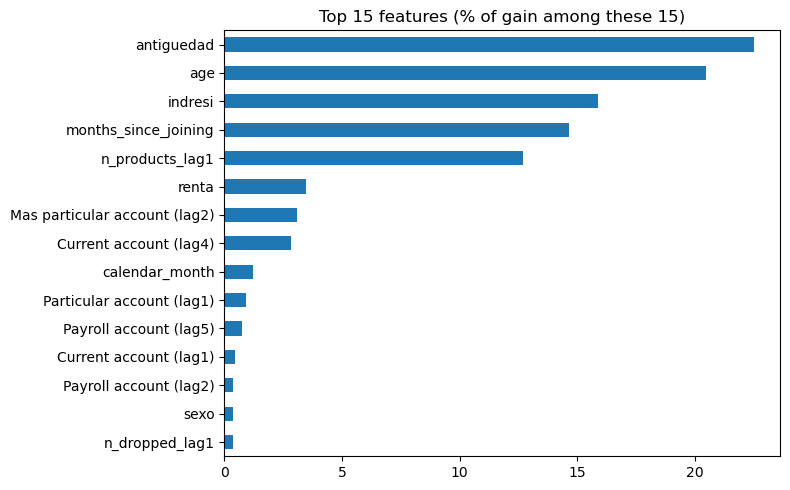

In [16]:
# Which features did the model lean on most? (total gain across all trees)
importance = (pd.Series(model.feature_importance("gain"), index=FEATURES_ALL)
              .sort_values(ascending=False).head(15))
def readable(name):
    base, _, k = name.rpartition("_lag")
    return f"{PRODUCT_NAMES[base]} (lag{k})" if base in PRODUCT_NAMES else name
importance.index = [readable(i) for i in importance.index]
fig, ax = plt.subplots(figsize=(8, 5))
(importance / importance.sum() * 100).sort_values().plot.barh(ax=ax)
ax.set_title("Top 15 features (% of gain among these 15)")
plt.tight_layout()
plt.show()

**Findings from the first model**
- Two engineered features made the top 5: **months since joining** and **products held last month**. That's an early sign they help; 4.3 tests it properly.
- **Why does `indresi` (lives in Spain) rank 3rd?** Hypothesis: non-residents can't use or don't need some products. Checked separately:
  - Non-residents are tiny: ~4,000 customers, 0.5% of rows.
  - They add **fewer** products overall (20 vs 35 per 1,000 customer-months), and almost never add **payroll, payroll pension, or a payroll account** (5–7x less often). Their salary probably isn't paid in Spain.
  - But they add **credit cards more often** (7.5 vs 5.5 per 1,000).
  - So it's less "no access" and more **a different product mix**. Because that group behaves so differently, splitting on it helps the model a lot, even though it's a small group.
- **Caveat:** *gain* importance shows what the model *uses*, not what matters most to the business. A small, unusual group can score high.

### 4.3 Experiments: let the validation month decide
Every combination of the three choices we deferred instead of guessing:

| Choice | Options |
|---|---|
| Training months | (a) recent 4 · (b) recent 4 + same month last year · (c) full previous year |
| Product history | 1 month (`HISTORY_1`) · 5 months (`HISTORY_1` + `HISTORY_2_5`) |
| Engineered features | on · off |

3 × 2 × 2 = **12 models**, same LightGBM settings, all scored on April 2016.

*Note:* "products dropped last month" compares 2 months back with 1 month back, so with engineered features **on**, the 1-month-history models still get a small hint from month 2.

In [17]:
experiments = []
for option in "abc":
    for history in (1, 5):
        for engineered in (False, True):
            features = (PROFILE + (ENGINEERED if engineered else [])
                        + HISTORY_1 + (HISTORY_2_5 if history == 5 else []))
            start = time.time()
            m = train_model(option, features)
            scores = m.predict(X_val[features], num_iteration=m.best_iteration)
            res = evaluate(scores, val_held, val_truth)
            experiments.append({"option": option, "history_months": history, "engineered": engineered,
                                **res, "rounds": m.best_iteration, "seconds": round(time.time() - start)})
            print(f"option {option} | history {history} | engineered {str(engineered):5} -> "
                  f"MAP@7 {res['MAP@7']:.5f}  hit@1 {res['hit@1']:.3f}  ({experiments[-1]['seconds']}s)")

exp = pd.DataFrame(experiments).sort_values("MAP@7", ascending=False).reset_index(drop=True)
exp.round(5)

option a | history 1 | engineered False -> MAP@7 0.02324  hit@1 0.732  (16s)
option a | history 1 | engineered True  -> MAP@7 0.02403  hit@1 0.757  (39s)
option a | history 5 | engineered False -> MAP@7 0.02487  hit@1 0.804  (19s)
option a | history 5 | engineered True  -> MAP@7 0.02522  hit@1 0.818  (25s)
option b | history 1 | engineered False -> MAP@7 0.02371  hit@1 0.749  (36s)
option b | history 1 | engineered True  -> MAP@7 0.02382  hit@1 0.751  (24s)
option b | history 5 | engineered False -> MAP@7 0.02481  hit@1 0.804  (19s)
option b | history 5 | engineered True  -> MAP@7 0.02466  hit@1 0.780  (25s)
option c | history 1 | engineered False -> MAP@7 0.02355  hit@1 0.745  (24s)
option c | history 1 | engineered True  -> MAP@7 0.02367  hit@1 0.745  (23s)
option c | history 5 | engineered False -> MAP@7 0.02486  hit@1 0.805  (26s)
option c | history 5 | engineered True  -> MAP@7 0.02496  hit@1 0.806  (27s)


,option,history_months,engineered,MAP@7,hit@3,hit@1,rounds,seconds
0,a,5,True,0.02522,0.94870,0.81817,19,25
1,c,5,True,0.02496,0.94085,0.80640,14,27
2,a,5,False,0.02487,0.94429,0.80428,9,19
3,c,5,False,0.02486,0.94165,0.80530,11,26
4,b,5,False,0.02481,0.93864,0.80394,7,19
5,b,5,True,0.02466,0.94369,0.78020,14,25
6,a,1,True,0.02403,0.93881,0.75744,38,39
7,b,1,True,0.02382,0.93605,0.75107,15,24
8,b,1,False,0.02371,0.93932,0.74912,30,36
9,c,1,True,0.02367,0.92564,0.74525,11,23


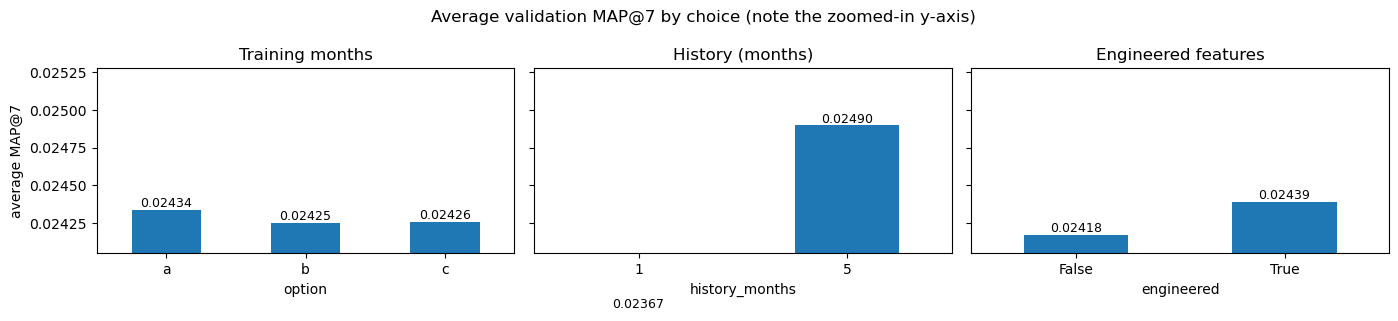

In [18]:
# How much did each choice move MAP@7, on average across the other settings?
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, col, title in zip(axes, ["option", "history_months", "engineered"],
                          ["Training months", "History (months)", "Engineered features"]):
    effect = exp.groupby(col)["MAP@7"].mean()
    effect.plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylim(effect.min() * 0.995, exp["MAP@7"].max() * 1.002)
    for i, v in enumerate(effect):
        ax.text(i, v, f"{v:.5f}", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("average MAP@7")
plt.suptitle("Average validation MAP@7 by choice (note the zoomed-in y-axis)")
plt.tight_layout()
plt.show()

### 4.4 Robustness check: is the winner real, or luck?
LightGBM samples random rows and features each round (`bagging_fraction`, `feature_fraction`), so two runs with different **random seeds** give slightly different scores. The top 3 setups in 4.3 were within 0.0003 of each other, and a gap that small could be luck.

**Two checks:**
1. **Seeds:** re-train the top 3 setups with seeds 1, 2, 3 and compare their **average** and **spread**.
2. **Learning rate:** most models stopped after under 40 rounds, which suggests learning rate 0.1 may be rushing. Try **0.05** (smaller steps, more trees) on the same 3 seeds.

A setup wins only if its average is ahead by more than the seed-to-seed spread.

In [19]:
SEEDS = [1, 2, 3]
TOP_SETUPS = [("a", 5, True), ("c", 5, True), ("a", 5, False)]

def features_for(history, engineered):
    return (PROFILE + (ENGINEERED if engineered else [])
            + HISTORY_1 + (HISTORY_2_5 if history == 5 else []))

checks = []
runs = [(s, 0.1) for s in TOP_SETUPS] + [(TOP_SETUPS[0], 0.05)]
for (option, history, engineered), lr in runs:
    feats = features_for(history, engineered)
    for seed in SEEDS:
        start = time.time()
        m = train_model(option, feats, seed=seed, learning_rate=lr)
        res = evaluate(m.predict(X_val[feats], num_iteration=m.best_iteration), val_held, val_truth)
        checks.append({"setup": f"({option}) / {history}m / eng {'on' if engineered else 'off'} / lr {lr}",
                       "seed": seed, **res, "rounds": m.best_iteration})
        print(f"{checks[-1]['setup']:32} seed {seed}: MAP@7 {res['MAP@7']:.5f}  "
              f"rounds {m.best_iteration}  ({time.time() - start:.0f}s)")

robust = (pd.DataFrame(checks).groupby("setup")
          .agg(MAP_mean=("MAP@7", "mean"), MAP_std=("MAP@7", "std"),
               hit3_mean=("hit@3", "mean"), hit1_mean=("hit@1", "mean"), rounds_mean=("rounds", "mean"))
          .sort_values("MAP_mean", ascending=False))
robust.round(5)

(a) / 5m / eng on / lr 0.1       seed 1: MAP@7 0.02509  rounds 40  (37s)
(a) / 5m / eng on / lr 0.1       seed 2: MAP@7 0.02524  rounds 15  (24s)
(a) / 5m / eng on / lr 0.1       seed 3: MAP@7 0.02515  rounds 13  (22s)
(c) / 5m / eng on / lr 0.1       seed 1: MAP@7 0.02490  rounds 11  (26s)
(c) / 5m / eng on / lr 0.1       seed 2: MAP@7 0.02497  rounds 16  (32s)
(c) / 5m / eng on / lr 0.1       seed 3: MAP@7 0.02495  rounds 12  (27s)
(a) / 5m / eng off / lr 0.1      seed 1: MAP@7 0.02469  rounds 7  (18s)
(a) / 5m / eng off / lr 0.1      seed 2: MAP@7 0.02494  rounds 12  (22s)
(a) / 5m / eng off / lr 0.1      seed 3: MAP@7 0.02484  rounds 11  (21s)
(a) / 5m / eng on / lr 0.05      seed 1: MAP@7 0.02542  rounds 81  (77s)
(a) / 5m / eng on / lr 0.05      seed 2: MAP@7 0.02525  rounds 36  (39s)
(a) / 5m / eng on / lr 0.05      seed 3: MAP@7 0.02543  rounds 67  (63s)


,MAP_mean,MAP_std,hit3_mean,hit1_mean,rounds_mean
setup,,,,,
(a) / 5m / eng on / lr 0.05,0.02537,0.00010,0.95074,0.82086,61.33333
(a) / 5m / eng on / lr 0.1,0.02516,0.00008,0.94795,0.81609,22.66667
(c) / 5m / eng on / lr 0.1,0.02494,0.00004,0.94000,0.80906,13.00000
(a) / 5m / eng off / lr 0.1,0.02482,0.00012,0.94399,0.80288,10.00000


### 4.5 Final test: May 2016 (unlocked once)
**Winning setup (from 4.3 + 4.4):** training option (a), 5 months of history, engineered features on, learning rate 0.05.

**What changes for the final run:**
- **Training months move forward one month:** option (a) for May 2016 = **Jan – Apr 2016**. April, our validation month, now becomes training data, since we're done using it to choose.
- **No early stopping.** Using May's additions to decide when to stop would let the test month influence the model. Instead the model trains for a **fixed number of rounds**: the average best round count of the winning setup in 4.4.
- **Nothing else is tuned after this.** The May score is reported as-is, alongside the popularity baseline for the same month.

In [20]:
WINNER = dict(option="a", history=5, engineered=True, learning_rate=0.05)
FINAL_ROUNDS = int(round(robust.loc["(a) / 5m / eng on / lr 0.05", "rounds_mean"]))
final_features = features_for(WINNER["history"], WINNER["engineered"])
final_months = training_months(WINNER["option"], TEST_MONTH_IDX)

tr = np.isin(month_train_all, final_months)
print(f"Training months: {final_months} (Jan-Apr 2016), {tr.sum():,} rows, {FINAL_ROUNDS} rounds")

start = time.time()
final_model = lgb.train({**PARAMS, "learning_rate": WINNER["learning_rate"]},
                        lgb.Dataset(X_train_all.loc[tr, final_features], y_train_all[tr]),
                        num_boost_round=FINAL_ROUNDS)
print(f"Trained in {time.time() - start:.0f}s")

# Score every May 2016 customer who was also a customer in April
test_rows, test_held, test_truth = eval_set(TEST_MONTH_IDX)
X_test = build_features(test_rows)
test_scores = final_model.predict(X_test[final_features])

test_popularity = np.bincount(y_train_all[tr], minlength=len(product_cols))
final_results = pd.DataFrame({
    "Popularity baseline": evaluate(np.tile(test_popularity, (len(test_rows), 1)), test_held, test_truth),
    "Final LightGBM": evaluate(test_scores, test_held, test_truth),
}).T
final_results.loc["Best possible"] = [test_truth.any(axis=1).mean(), 1.0, 1.0]
print(f"\nTest month: {len(test_rows):,} customers, {test_truth.any(axis=1).mean():.2%} added something")
final_results.round(5)

Training months: [12, 13, 14, 15] (Jan-Apr 2016), 148,145 rows, 61 rounds
Trained in 28s

Test month: 926,663 customers, 3.01% added something


,MAP@7,hit@3,hit@1
Popularity baseline,0.01939,0.86520,0.52102
Final LightGBM,0.02671,0.96598,0.83693
Best possible,0.03008,1.00000,1.00000


## 5. Evaluation
Phase 4 answered *"how good is the score?"* Phase 5 asks *"does it meet the business goal, and where does it fall short?"*

**The manager's question:** *"Will it actually sell more products than RMs do now?"*

**What this data can and can't answer:** the data has no campaign history (Section 1.6). The model predicts what customers were **going to add anyway**, not what an RM's pitch would **cause** them to add. So:
- **The data can show:** how well the model ranks what each customer wants, compared with a generic list.
- **Only a pilot can show:** extra products sold because of the list (5.4).

### 5.1 Performance by product
For every product, among May customers who actually added it: how often did the model rank it **#1**, in the **top 3**, and in the **top 7**? (Ranks are among products the customer didn't already hold.)

In [21]:
# Rank of every product for every test customer (0 = top recommendation)
s = np.where(test_held, -np.inf, test_scores)
order = np.argsort(-s, axis=1)
rank = np.empty_like(order)
rank[np.arange(len(order))[:, None], order] = np.arange(order.shape[1])

per_product = []
for j, col in enumerate(product_cols):
    adders = test_truth[:, j]
    if adders.sum() == 0:
        continue
    r = rank[adders, j]
    per_product.append({"product": PRODUCT_NAMES[col], "pitchable": col in pitchable_cols,
                        "May additions": int(adders.sum()),
                        "ranked #1 %": (r == 0).mean() * 100,
                        "top 3 %": (r < 3).mean() * 100,
                        "top 7 %": (r < 7).mean() * 100})

per_product = pd.DataFrame(per_product).sort_values("May additions", ascending=False).set_index("product")
per_product.round(1)

,pitchable,May additions,ranked #1 %,top 3 %,top 7 %
product,,,,,
Direct debit,True,10163,89.5,99.5,100.0
Pension (paid via payroll),False,5513,40.0,94.3,100.0
Payroll (salary deposit),False,5488,30.1,92.1,99.9
Credit card,True,4248,72.1,92.8,98.9
Current account,True,3854,93.7,98.3,100.0
e-account,True,2709,62.9,86.4,99.9
Payroll account,True,2346,47.9,65.0,99.6
Mas particular account,True,512,23.6,81.6,97.3
Taxes,True,279,10.8,44.1,95.3


**Findings**
1. **Strong on everyday payment products:** direct debit (ranked #1 for 90% of customers who added it), current account (94%), credit card (72%).
2. **Weak on investment and savings products:** funds (3% ranked #1, 7% in the top 3), securities (30% top 3), long-term deposit (44% top 3), taxes (44% top 3).
3. **Two reasons, stacked:** investment products are **rare** (60 fund additions in May vs 10,163 direct debits), so the model has few examples to learn from, *and* they're less predictable from profile and history.

**The tension:** customers tend to add everyday products **on their own**. Investment products are the ones that more likely **need an RM's pitch**. So the model is *best* where an RM adds the least value and *weakest* where an RM adds the most. The 84% first-pitch hit rate overstates the business value, since many of those "hits" would have happened without a call.

### 5.2 Flip the list: product-first campaign lists
So far each customer gets a ranked list of products. Now we flip it: **for one product, rank all customers.** For example, *"Which customers are most likely to add funds next month?"* That's how an investment campaign call list would be built.

**Metric: lift.** If we call the model's top 1% of customers for a product, how many times more likely are they to add it than an average customer? Lift 10 = ten times the normal rate.
- **Capture** = what share of *all* the customers who added that product were in the top slice.
- Only customers who **don't already hold** the product are ranked.

*Caveat:* the model's probabilities answer "*if* this customer adds something, how likely is it this product?" A customer who rarely adds anything can still score high. A dedicated "will they add anything?" model could sharpen these lists later.

In [22]:
CAMPAIGN_PRODUCTS = ["ind_fond_fin_ult1", "ind_valo_fin_ult1", "ind_dela_fin_ult1",
                     "ind_reca_fin_ult1", "ind_ctpp_fin_ult1", "ind_ctma_fin_ult1", "ind_cno_fin_ult1",
                     "ind_tjcr_fin_ult1"]

# (Short-term deposit left out: zero additions in May 2016, so lift is undefined)
lift_rows, gains = [], {}
for col in CAMPAIGN_PRODUCTS:
    j = product_cols.index(col)
    eligible = ~test_held[:, j]
    score, added_j = test_scores[eligible, j], test_truth[eligible, j]
    ranked = added_j[np.argsort(-score)]              # outcomes, best-scored customer first
    base_rate = added_j.mean()
    row = {"product": PRODUCT_NAMES[col], "May adders": int(added_j.sum()),
           "base rate per 1,000": base_rate * 1000}
    for pct in (1, 5, 10):
        top = ranked[: int(len(ranked) * pct / 100)]
        row[f"lift top {pct}%"] = top.mean() / base_rate
        row[f"capture top {pct}%"] = top.sum() / added_j.sum() * 100
    lift_rows.append(row)
    gains[PRODUCT_NAMES[col]] = np.cumsum(ranked) / added_j.sum()

lift_table = pd.DataFrame(lift_rows).set_index("product")
lift_table.round(1)

,May adders,"base rate per 1,000",lift top 1%,capture top 1%,lift top 5%,capture top 5%,lift top 10%,capture top 10%
product,,,,,,,,
Funds,60,0.1,10.0,10.0,6.3,31.7,4.0,40.0
Securities,183,0.2,33.3,33.3,9.8,49.2,5.7,56.8
Long-term deposit,46,0.1,50.0,50.0,11.7,58.7,6.3,63.0
Taxes,279,0.3,4.7,4.7,2.7,13.6,1.9,19.4
Particular Plus account,131,0.1,54.2,54.2,13.7,68.7,7.2,71.8
Mas particular account,512,0.6,73.4,73.4,18.4,91.8,9.4,93.9
Payroll account,2346,2.7,53.6,53.6,13.2,65.8,7.5,75.4
Credit card,4248,4.8,43.9,43.9,14.8,74.2,8.2,81.7


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_134128\789496882.py:13: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\Lenovo\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


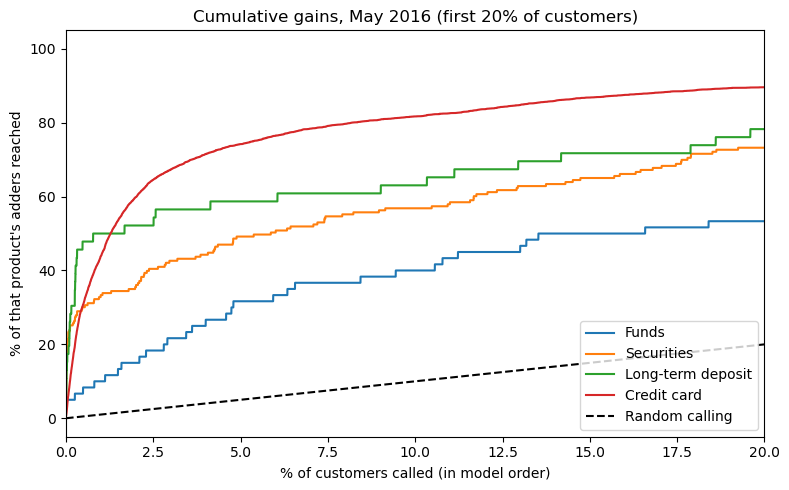

In [23]:
# Cumulative gains: call customers in model order; what share of the product's adders have we reached?
fig, ax = plt.subplots(figsize=(8, 5))
for name in ["Funds", "Securities", "Long-term deposit", "Credit card"]:
    g = gains[name]
    x = np.arange(1, len(g) + 1) / len(g) * 100
    ax.plot(x, g * 100, label=name)
ax.plot([0, 100], [0, 100], "k--", label="Random calling")
ax.set_xlim(0, 20)
ax.set_xlabel("% of customers called (in model order)")
ax.set_ylabel("% of that product's adders reached")
ax.set_title("Cumulative gains, May 2016 (first 20% of customers)")
ax.legend()
plt.tight_layout()
plt.savefig("images/cumulative_gains.png", dpi=150, bbox_inches="tight")   # used in the README
plt.show()

**Findings**
1. **Flipping the list rescues most of the weak products.** Products that rarely rank #1 in a customer's list still get strong lift: Mas particular 73x, Particular Plus 54x, long-term deposit 50x, securities 33x, funds 10x (top 1%). Calling the top 10% for funds reaches 40% of fund adders, vs 10% for random calling.
2. **Taxes stays weak (4.7x).** Paying taxes through the bank is driven by the **calendar** (Spain's tax campaign runs around April to June), not by who the customer is. Also, the winning setup trains on Jan–Apr only, so it never saw last year's tax season; option (c) would have. This is a known cost of choosing recent data.
3. **Lift is relative; check the absolute rate too.** Funds has a tiny base rate (~0.07 per 1,000), so even 10x lift is only about **1 adder per 1,500 calls**. Securities (33x on ~0.2 per 1,000) is about **7 per 1,000 calls**. Whether a list is worth calling depends on the value of a sale and the cost of a call, which this data doesn't include.
4. **These are natural adders.** The lists find customers who added the product *without* a known pitch. The number that decides ROI is how many *extra* customers say yes **because** they were called. Only a pilot can measure that (5.4).

**So what:** use the model **two ways**. Customer-first lists for everyday products, and **product-first campaign lists** for investment and premium-account products, where a pitch likely matters more.

### 5.2b Which customers get poor recommendations?
Same May 2016 test, split by customer type. Only customers who **added something** are included, since everyone else scores 0 no matter what.

- **Average precision (AP):** each adder's MAP@7 score (1.0 = their product was ranked #1). The group average shows ranking quality *within* the group.
- **Hit @ 1:** for adders of a pitchable product, was the RM's first pitch right?
- **vs baseline:** the same numbers for the popularity list, so we can see where the model adds the most and least.

Groups: new customers (joined < 6 months ago), non-residents, unknown profile (2.3), segment, and age group.

In [24]:
def per_customer(scores, held, truth):
    """Average precision per customer, and hit@1 on pitchable products."""
    s = np.where(held, -np.inf, scores.astype("float64"))
    top7 = np.argsort(-s, axis=1)[:, :7]
    rel = np.take_along_axis(truth, top7, axis=1)
    n_true = truth.sum(axis=1)
    ap = (np.cumsum(rel, axis=1) / np.arange(1, 8) * rel).sum(axis=1) / np.minimum(n_true, 7).clip(min=1)
    first_pitch = pitchable_idx[np.argmax(s[:, pitchable_idx], axis=1)]
    hit1 = truth[np.arange(len(truth)), first_pitch]
    return ap, hit1

model_ap, model_hit1 = per_customer(test_scores, test_held, test_truth)
base_ap, base_hit1 = per_customer(np.tile(test_popularity, (len(test_rows), 1)), test_held, test_truth)

adder = test_truth.any(axis=1)
pitch_adder = test_truth[:, pitchable_idx].any(axis=1)

age_t = X_test["age"]
groups_t = {
    "New customer (< 6 months)": X_test["months_since_joining"] < 6,
    "Non-resident": X_test["indresi"] == "N",
    "Unknown profile": X_test["profile_unknown"] == 1,
    "Segment: VIP": X_test["segmento"] == "01 - TOP",
    "Segment: individuals": X_test["segmento"] == "02 - PARTICULARES",
    "Segment: students": X_test["segmento"] == "03 - UNIVERSITARIO",
    "Age < 25": age_t < 25,
    "Age 25-44": age_t.between(25, 44),
    "Age 45-64": age_t.between(45, 64),
    "Age 65+": age_t >= 65,
    "All adders": pd.Series(True, index=X_test.index),
}

rows = []
for name, mask in groups_t.items():
    m = mask.to_numpy() & adder
    mp = mask.to_numpy() & pitch_adder
    rows.append({"group": name, "adders": int(m.sum()),
                 "model AP": model_ap[m].mean(), "baseline AP": base_ap[m].mean(),
                 "model hit@1 %": model_hit1[mp].mean() * 100, "baseline hit@1 %": base_hit1[mp].mean() * 100})

by_group = pd.DataFrame(rows).set_index("group")
by_group["AP gain vs baseline"] = by_group["model AP"] - by_group["baseline AP"]
by_group.round(3)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_134128\1966600615.py:38: RuntimeWarning: Mean of empty slice.
  "model AP": model_ap[m].mean(), "baseline AP": base_ap[m].mean(),
c:\Users\Lenovo\anaconda3\Lib\site-packages\numpy\_core\_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_134128\1966600615.py:39: RuntimeWarning: Mean of empty slice.
  "model hit@1 %": model_hit1[mp].mean() * 100, "baseline hit@1 %": base_hit1[mp].mean() * 100})


,adders,model AP,baseline AP,model hit@1 %,baseline hit@1 %,AP gain vs baseline
group,,,,,,
New customer (< 6 months),4062,0.876,0.464,81.776,29.627,0.412
Non-resident,72,0.809,0.486,72.464,44.928,0.323
Unknown profile,0,NaN,NaN,NaN,NaN,NaN
Segment: VIP,3145,0.894,0.534,84.618,36.545,0.360
Segment: individuals,20025,0.882,0.646,82.749,52.613,0.236
Segment: students,4699,0.910,0.714,87.247,61.136,0.196
Age < 25,2428,0.910,0.645,86.630,55.784,0.265
Age 25-44,13839,0.891,0.673,84.154,54.672,0.217
Age 45-64,9740,0.882,0.629,82.765,50.434,0.254


**Findings**
1. **Consistent across groups.** Average precision ranges 0.81–0.91 in every group, so no customer type gets badly served.
2. **Biggest gains where customers are least "average":** new customers (first-pitch hit 30% → 82%), VIPs (37% → 85%), age 65+ (39% → 82%). A popularity list is effectively a portrait of the typical long-standing customer. New customers are still setting up basics (current account, payroll account), VIPs lean toward credit cards and premium accounts, and older customers have pension-linked patterns. All of these sit low in a generic list.
3. **Students gain least (61% → 87%)** because what they add (simple everyday products) already matches the top of the popular list.
4. **Non-residents score lowest (0.81)**, but with only 72 adders the estimate is unreliable.
5. **Unknown-profile customers: 0 in May 2016**, confirming the 2.3 finding that those rows disappear after mid-2015.

**So what:** start an RM pilot with **new customers and VIPs**, where the model beats a generic list by the widest margin. Onboarding is also a high-value moment for cross-selling.

### 5.3 The business translation: per 1,000 conversations
A manager doesn't think in MAP@7. The question here is:

> *Out of 1,000 RM conversations with customers, how many times does the RM's **first pitch** match a pitchable product the customer actually opened that month?*

This counts **all** customers, including the ~97% who open nothing that month, so it's an honest per-conversation number, not just "accuracy among buyers." It's shown for everyone and for the two pilot groups from 5.2b (new customers, VIPs).

*Reminder:* these are matches with **natural demand**, products customers opened anyway. They show the list points RMs at the right product. They do **not** show extra sales caused by the pitch.

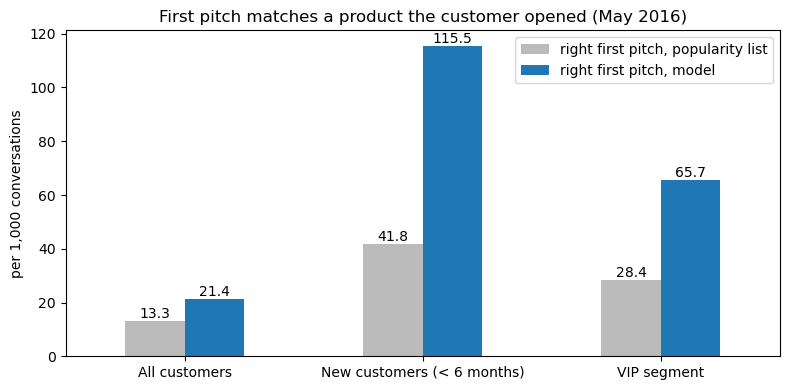

,customers,"open a pitchable product (per 1,000)","right first pitch, popularity list","right first pitch, model",extra right first pitches,% more
All customers,926663.0,25.5,13.3,21.4,8.1,60.6
New customers (< 6 months),27509.0,141.2,41.8,115.5,73.6,176.0
VIP segment,35415.0,77.7,28.4,65.7,37.3,131.5


In [25]:
def per_1000(mask):
    m = mask.to_numpy() if hasattr(mask, "to_numpy") else mask
    opened = pitch_adder[m].mean() * 1000
    return {"customers": int(m.sum()),
            "open a pitchable product (per 1,000)": opened,
            "right first pitch, popularity list": base_hit1[m & pitch_adder].mean() * opened,
            "right first pitch, model": model_hit1[m & pitch_adder].mean() * opened}

translation = pd.DataFrame({
    "All customers": per_1000(np.ones(len(test_rows), dtype=bool)),
    "New customers (< 6 months)": per_1000(groups_t["New customer (< 6 months)"]),
    "VIP segment": per_1000(groups_t["Segment: VIP"]),
}).T
translation["extra right first pitches"] = (translation["right first pitch, model"]
                                            - translation["right first pitch, popularity list"])
translation["% more"] = (translation["right first pitch, model"]
                         / translation["right first pitch, popularity list"] - 1) * 100

ax = translation[["right first pitch, popularity list", "right first pitch, model"]].plot.bar(
    figsize=(8, 4), rot=0, color=["#bbbbbb", "#1f77b4"])
ax.set_ylabel("per 1,000 conversations")
ax.set_title("First pitch matches a product the customer opened (May 2016)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f")
plt.tight_layout()
plt.savefig("images/right_first_pitch_per_1000.png", dpi=150, bbox_inches="tight")   # used in the README
plt.show()

translation.round(1)

**Findings**
1. **All customers:** the model's first pitch matches a product the customer actually opened **21.4 times per 1,000 conversations**, vs **13.3** for a generic popularity list, about **60% more**.
2. **New customers (< 6 months):** they're ~5.5x more likely to open something (141 per 1,000 vs 25.5 overall), *and* that's where the model gains most: **115.5 vs 41.8** right first pitches per 1,000, almost **3x**.
3. **VIPs:** **65.7 vs 28.4** per 1,000, about **2.3x**.

**Summary for a bank manager:**
> The model gets the RM's first pitch right about 60% more often than a generic list. With new customers, it's almost three times as often. But this data can't tell us if that means extra sales. So I'd start with a small pilot on new customers, and measure it.

### 5.4 Deploy decision and pilot design

**Verdict: ready for a pilot, not a full rollout.**
- **Proven by this data:** the model ranks what customers want far better than a generic list: 89% of the best possible MAP@7, ~60% more right first pitches overall, ~3x for new customers. Validation and test agree, so it isn't overfit.
- **Not proven:** that RM pitches using the list **cause** extra sales. The data has no campaign history, so the model learned *natural* demand.

**Pilot design**

| Question | Answer |
|---|---|
| **Who** | New customers (joined < 6 months ago), where the model helps most (5.2b, 5.3) |
| **How** | Randomly split RMs into two groups: one uses the model's list, the other works as usual |
| **How long** | 3 months, to smooth out one-off monthly spikes like Feb 2016 |
| **Main metric** | Pitchable products opened per customer, model group vs usual group |
| **Also track** | Products closed again within 3 months, to catch customers being pushed into products they don't want |
| **Go / no-go** | Roll out if the model group opens meaningfully more products **and** doesn't close more of them |

**How big does the pilot need to be?** Below: the number of customers per group needed to reliably detect a given improvement in the share of new customers who open a pitchable product. Standard settings: 5% false-alarm rate (significance), 80% chance of catching a real effect (power).

*Caveat:* randomizing **RMs** rather than individual customers means customers of the same RM aren't fully independent, so the real requirement is somewhat higher than this simple calculation.

In [26]:
from scipy.stats import norm

def n_per_group(p0, relative_lift, alpha=0.05, power=0.80):
    """Customers per group for a two-sided test of two proportions."""
    p1 = p0 * (1 + relative_lift)
    p_bar = (p0 + p1) / 2
    z_a, z_b = norm.ppf(1 - alpha / 2), norm.ppf(power)
    n = (z_a * np.sqrt(2 * p_bar * (1 - p_bar)) + z_b * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p1 - p0) ** 2
    return int(np.ceil(n))

new_mask = groups_t["New customer (< 6 months)"].to_numpy()
p0 = pitch_adder[new_mask].mean()          # share of new customers opening a pitchable product in a month
available_per_group = new_mask.sum() // 2

print(f"Baseline: {p0:.1%} of new customers open a pitchable product in a month")
print(f"New customers available right now: {new_mask.sum():,} (~{available_per_group:,} per group)\n")

sizes = pd.DataFrame([
    {"improvement to detect": f"+{lift:.0%}", "new rate": f"{p0 * (1 + lift):.1%}",
     "customers needed per group": n_per_group(p0, lift)}
    for lift in (0.05, 0.10, 0.20, 0.30)
]).set_index("improvement to detect")
sizes["enough with current pool?"] = np.where(sizes["customers needed per group"] <= available_per_group, "yes", "no")
sizes

Baseline: 14.1% of new customers open a pitchable product in a month
New customers available right now: 27,509 (~13,754 per group)



,new rate,customers needed per group,enough with current pool?
improvement to detect,,,
+5%,14.8%,38975,no
+10%,15.5%,9940,yes
+20%,16.9%,2581,yes
+30%,18.4%,1189,yes


**Sample size findings**
- 14.1% of new customers open a pitchable product in a given month. About 27,500 new customers are available, ~13,750 per group.
- That's enough to reliably detect a **+10% or larger** improvement (needs ~9,900 per group), but **not +5%** (needs ~39,000).
- So the pilot can catch a meaningful effect, but a small one would need a longer pilot or a wider customer group. Since RMs (not customers) are randomized, a margin above these numbers is wise.

## 6. Deployment

### 6.1 Sample RM call list
What an RM in the pilot group would actually see: **10 new customers** (joined < 6 months ago) from May 2016, each with a short profile and their **top 3 pitchable products**, in ranked order.

The last column shows what the customer **actually opened** that month. An RM wouldn't have this; it's here so we can see the list working (and missing) on real cases. The 10 customers are picked at random with a fixed seed, so the list is reproducible.

**Why no percentages?** The model's probabilities mean *"**if** this customer opens something, how likely is it this product?"* A label like "Current account (88%)" would read as an 88% chance they open one, when only ~14% of new customers open anything in a month. Showing the rank only avoids that misreading.

In [27]:
SEGMENT_NAMES = {"01 - TOP": "VIP", "02 - PARTICULARES": "Individual", "03 - UNIVERSITARIO": "Student"}

def top_pitches(i, k=3):
    """Top-k pitchable products for test customer i, skipping what they already hold."""
    s = np.where(test_held[i], -np.inf, test_scores[i])[pitchable_idx]
    best = pitchable_idx[np.argsort(-s)[:k]]
    return [PRODUCT_NAMES[product_cols[j]] for j in best]

def describe(i):
    x = X_test.iloc[i]
    held = [PRODUCT_NAMES[product_cols[j]] for j in np.flatnonzero(test_held[i])]
    opened = [PRODUCT_NAMES[product_cols[j]] for j in np.flatnonzero(test_truth[i])]
    return {
        "customer ID": int(df["ncodpers"].iloc[test_rows[i]]),
        "profile": (f"{int(x['age'])} yrs, {SEGMENT_NAMES.get(x['segmento'], 'Unknown')}, "
                    f"income ~EUR {x['renta'] / 1000:.0f}k, joined {int(x['months_since_joining'])} mo ago"),
        "holds now": ", ".join(held) or "nothing",
        "pitch 1": top_pitches(i)[0], "pitch 2": top_pitches(i)[1], "pitch 3": top_pitches(i)[2],
        "actually opened in May": ", ".join(opened) or "nothing",
    }

rng = np.random.default_rng(7)
new_customers = np.flatnonzero(groups_t["New customer (< 6 months)"].to_numpy())
sample = rng.choice(new_customers, size=10, replace=False)

call_list = pd.DataFrame([describe(i) for i in sample]).set_index("customer ID")
pd.set_option("display.max_colwidth", 60)
call_list

,profile,holds now,pitch 1,pitch 2,pitch 3,actually opened in May
customer ID,,,,,,
1533799,"66 yrs, Individual, income ~EUR 66k, joined 3 mo ago",nothing,Current account,Direct debit,Payroll account,nothing
1544180,"49 yrs, Individual, income ~EUR 130k, joined 1 mo ago",Current account,Mas particular account,Direct debit,Payroll account,Direct debit
1539445,"45 yrs, Individual, income ~EUR 69k, joined 2 mo ago","Current account, Direct debit",Taxes,Payroll account,Credit card,nothing
1541716,"26 yrs, Student, income ~EUR 68k, joined 2 mo ago",nothing,Current account,Direct debit,Payroll account,nothing
1531969,"28 yrs, Student, income ~EUR 64k, joined 3 mo ago","Current account, Taxes",Direct debit,Payroll account,e-account,nothing
1521312,"40 yrs, Individual, income ~EUR 101k, joined 4 mo ago","Current account, Direct debit",Payroll account,Taxes,e-account,nothing
1546053,"41 yrs, Individual, income ~EUR 82k, joined 1 mo ago",nothing,Current account,Direct debit,Payroll account,nothing
1512650,"22 yrs, Student, income ~EUR 87k, joined 5 mo ago",Current account,Direct debit,Payroll account,Taxes,nothing
1518539,"35 yrs, Individual, income ~EUR 72k, joined 5 mo ago",Current account,Direct debit,Payroll account,Taxes,nothing


**Same view, customers who *did* open something.** Since only ~14% of new customers open a product in a given month, a random sample is mostly "nothing." Below are 5 random new customers who opened at least one pitchable product, to show what hits and misses look like.

In [28]:
opened_pitchable = np.flatnonzero(groups_t["New customer (< 6 months)"].to_numpy() & pitch_adder)
sample_hits = rng.choice(opened_pitchable, size=5, replace=False)

hits_list = pd.DataFrame([describe(i) for i in sample_hits]).set_index("customer ID")
hits_list["first pitch right?"] = ["yes" if row["pitch 1"] in row["actually opened in May"] else "no"
                                   for _, row in hits_list.iterrows()]
hits_list

,profile,holds now,pitch 1,pitch 2,pitch 3,actually opened in May,first pitch right?
customer ID,,,,,,,
1525917,"56 yrs, Individual, income ~EUR 136k, joined 4 mo ago","Current account, Mas particular account, Direct debit",e-account,Taxes,Payroll account,e-account,yes
1533213,"54 yrs, Individual, income ~EUR 82k, joined 3 mo ago","Current account, Mas particular account",e-account,Direct debit,Payroll account,e-account,yes
1526873,"80 yrs, VIP, income ~EUR 105k, joined 4 mo ago","Current account, Mas particular account",e-account,Direct debit,Payroll account,e-account,yes
1545955,"48 yrs, Individual, income ~EUR 130k, joined 1 mo ago",nothing,Current account,Mas particular account,Direct debit,Current account,yes
1528394,"55 yrs, Individual, income ~EUR 130k, joined 4 mo ago",Mas particular account,e-account,Current account,Direct debit,e-account,yes


### 6.2 Sample campaign list: funds
The "flip the list" idea from 5.2: instead of the best product for one customer, the **best customers for one product**. This is what an investment campaign team would hand to RMs.

- Ranked by the model's funds score, among May 2016 customers who **don't already hold funds**.
- The top 20 are shown with a short profile, plus the summary for the **top 1%** (the 10x lift slice from 5.2).
- As in 6.1, *opened funds in May* is shown only to check the list; a campaign team wouldn't know it in advance.

In [29]:
FUNDS = product_cols.index("ind_fond_fin_ult1")
eligible = np.flatnonzero(~test_held[:, FUNDS])
ranked = eligible[np.argsort(-test_scores[eligible, FUNDS])]

def campaign_row(i, rank):
    d = describe(i)
    return {"rank": rank, "customer ID": d["customer ID"], "profile": d["profile"],
            "holds now": d["holds now"], "opened funds in May": "yes" if test_truth[i, FUNDS] else "no"}

funds_list = pd.DataFrame([campaign_row(i, r) for r, i in enumerate(ranked[:20], 1)]).set_index("rank")

top1 = ranked[: len(ranked) // 100]
print(f"Customers eligible for a funds pitch: {len(ranked):,}")
print(f"Top 1% = {len(top1):,} customers -> {test_truth[top1, FUNDS].sum()} opened funds "
      f"({test_truth[top1, FUNDS].mean() * 1000:.2f} per 1,000 vs {test_truth[eligible, FUNDS].mean() * 1000:.2f} overall)")
print(f"Top 20 -> {test_truth[ranked[:20], FUNDS].sum()} opened funds\n")
funds_list

Customers eligible for a funds pitch: 911,848
Top 1% = 9,118 customers -> 6 opened funds (0.66 per 1,000 vs 0.07 overall)
Top 20 -> 1 opened funds



,customer ID,profile,holds now,opened funds in May
rank,,,,
1,999115,"49 yrs, Individual, income ~EUR 150k, joined 53 mo ago","Current account, e-account, Pension plan, Securities",yes
2,23154,"42 yrs, Individual, income ~EUR 114k, joined 220 mo ago",Current account,no
3,268782,"55 yrs, Individual, income ~EUR 108k, joined 177 mo ago","Current account, Particular account, Pension plan",no
4,311041,"61 yrs, Individual, income ~EUR 146k, joined 173 mo ago","Current account, Pension plan",no
5,153719,"74 yrs, VIP, income ~EUR 113k, joined 151 mo ago","Current account, Particular account, Credit card, Securi...",no
6,410874,"43 yrs, Individual, income ~EUR 108k, joined 158 mo ago","Current account, Particular Plus account, e-account",no
7,516113,"90 yrs, Individual, income ~EUR 108k, joined 135 mo ago",Current account,no
8,220918,"68 yrs, VIP, income ~EUR 163k, joined 183 mo ago","Payroll account, e-account, Pension (paid via payroll)",no
9,1248131,"54 yrs, Individual, income ~EUR 70k, joined 26 mo ago","Current account, e-account, Securities",no


**Who does the model think is "funds-ready"?** Older, higher-income, long-standing customers (mostly 10+ years) who **already hold investment products** like pension plans and securities. People who already invest are the likeliest to invest more. That matches what an experienced RM would expect, which matters: a list that makes sense to RMs is a list they'll actually use.

Top 1% (~9,100 customers): 6 opened funds, 0.66 per 1,000 vs 0.07 overall (10x). The #1-ranked customer opened funds that month.

### 6.3 A reusable `recommend()` function
So far the model has been used in bulk. In practice an RM looks up **one customer at a time**. `recommend()` takes a customer ID and returns their profile, what they hold, and their top pitchable products, ready to show in a CRM screen or app.

It works for any customer in the May 2016 snapshot. In production, the same function would run on the latest month's data, with the model retrained regularly (e.g. monthly) on the most recent 4 months, matching the winning setup.

In [30]:
test_position = pd.Series(np.arange(len(test_rows)), index=df["ncodpers"].iloc[test_rows].to_numpy())

def recommend(customer_id, k=3):
    """Top-k pitchable products for one customer (May 2016 snapshot)."""
    if customer_id not in test_position.index:
        return f"Customer {customer_id} is not in the May 2016 snapshot."
    i = test_position[customer_id]
    d = describe(i)
    s = np.where(test_held[i], -np.inf, test_scores[i])[pitchable_idx]
    picks = [PRODUCT_NAMES[product_cols[j]] for j in pitchable_idx[np.argsort(-s)[:k]]]
    lines = [f"Customer {customer_id}: {d['profile']}",
             f"  Holds now: {d['holds now']}"]
    lines += [f"  Pitch {n}: {p}" for n, p in enumerate(picks, 1)]
    return "\n".join(lines)

# Try it on a few customers from the lists above
for cid in [1544180, 999115, 1533799]:
    print(recommend(cid), "\n")
print(recommend(123))

Customer 1544180: 49 yrs, Individual, income ~EUR 130k, joined 1 mo ago
  Holds now: Current account
  Pitch 1: Mas particular account
  Pitch 2: Direct debit
  Pitch 3: Payroll account 

Customer 999115: 49 yrs, Individual, income ~EUR 150k, joined 53 mo ago
  Holds now: Current account, e-account, Pension plan, Securities
  Pitch 1: Funds
  Pitch 2: Direct debit
  Pitch 3: Credit card 

Customer 1533799: 66 yrs, Individual, income ~EUR 66k, joined 3 mo ago
  Holds now: nothing
  Pitch 1: Current account
  Pitch 2: Direct debit
  Pitch 3: Payroll account 

Customer 123 is not in the May 2016 snapshot.


## Conclusion

| | |
|---|---|
| **Business question** | Which product should an RM pitch next, to each customer? |
| **Answer** | A LightGBM model using profile + 5 months of product history. On the locked May 2016 test it reaches 89% of the best possible MAP@7 (baseline: 64%) and gets the RM's first pitch right 84% of the time (baseline: 52%). |
| **Where it helps most** | New customers (first pitch right almost 3x as often) and VIPs. |
| **Where it's weak** | Rare investment products. Flipping to product-first campaign lists recovers much of that (funds: 10x lift in the top 1%). |
| **What it can't prove** | Extra sales caused by pitching. The data has no campaign history. |
| **Recommendation** | A 3-month pilot with new customers, RMs randomly split, ~9,900 customers per group to detect a +10% improvement. |